# Five-second epoch spectra of CCA-projected EEG

First construct **U17 and U19 over each complete recorded trial**. Then split those already projected waveforms into consecutive five-second epochs starting at trial onset. CCA is never fitted to the one-second epochs.

There are exactly **two batches of 12 independently copyable figures**. Each batch contains Paddle and Leaf, each with three trial groups (Left/C1, Right/C2 and all trials) and two averaging orders. The first batch uses weights fitted once using the complete trial. The second uses the latest one-second CCA fit at each logged neurofeedback update, approximately every 100 ms. Each spectrum shows both independent target projections. No matched-window figures or heat maps are included.

Each figure has a short title and a detailed caption. Figures remain separate inside notebook tables and are exported as PNG and SVG files in `plots/cca_5s_epoch_plots`.

In [1]:
from pathlib import Path
from functools import lru_cache
import base64
import html
import io
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import HTML, display

ROOT = Path.cwd()
if not (ROOT / 'data/2026-10-06').is_dir():
    ROOT = Path(r'C:\Users\Kalyanbrata\Documents\Android\Analysis')
DATA_ROOT = ROOT / 'data/2026-10-06'
PLOT_EXPORT_DIR = ROOT / 'plots' / '2026-10-06_cca_epoch_spectra_5s'
PLOT_EXPORT_DPI = 200
FILES = {'Paddle': ('eeg_20261006_153213', 'eeg_20261006_155629'),
         'Leaf': ('eeg_20261006_160348', 'eeg_20261006_161145')}
LABELS = {'Paddle': {20: 'Left target', 21: 'Right target'},
          'Leaf': {20: 'C1 / Pointing', 21: 'C2 / Moving'}}
CHANNEL_COLUMNS = [f'ch{i}_uv' for i in range(9, 25)]
CHANNEL_NAMES = [f'C{i}' for i in range(9, 25)]
FS, TARGETS_HZ = 250.0, (17.0, 19.0)
NF_WINDOW_SECONDS, NF_HOP_SECONDS = 1.0, 0.1
WINDOW_SAMPLES = int(round(FS * NF_WINDOW_SECONDS))
HOP_SAMPLES = int(round(FS * NF_HOP_SECONDS))
# Fixed electrode polarity convention, not reference-phase alignment.
SIGN_ANCHOR_CHANNEL = 'ch16_uv'
SIGN_ANCHOR_INDEX = CHANNEL_COLUMNS.index(SIGN_ANCHOR_CHANNEL)
# None shows all NF points; set a duration only to restrict the displayed maps.
PLOT_MAX_SECONDS, FREQ_LIMITS = None, (5.0, 30.0)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .18, 'font.size': 10})
# Overview spectra retain complete variable-duration trials.
EPOCH_SECONDS = 2.0
EPOCH_SAMPLES = int(round(FS * EPOCH_SECONDS))
PLOT_EXPORT_DIR = ROOT / 'plots' / f'2026-10-06_cca_epoch_spectra_{EPOCH_SECONDS:g}s'
PLOT_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

## Load the original recordings

Use the same four October 6 recordings and board-filtered C9–C24 signals at 250 Hz. Markers 20/21 start trials; marker 30 ends them. The existing 16-channel analysis selection is retained. No extra filtering or channel averaging is performed before CCA. Actual logged `is_cca == 1` sample endpoints determine the one-second refits.

In [2]:
def marker_starts(markers, values):
    return np.flatnonzero(np.isin(markers, values) &
                         np.r_[True, markers[1:] != markers[:-1]])

records, trials, recording_rows = [], [], []
for game, stamps in FILES.items():
    for block, stamp in enumerate(stamps, 2):
        folder = DATA_ROOT / stamp
        s = pd.read_csv(folder / f'{stamp}_signals.csv',
                        usecols=['seq', 'marker', *CHANNEL_COLUMNS])
        f = pd.read_csv(folder / f'{stamp}_features.csv', usecols=['seq', 'is_cca'])
        seq, markers = s.seq.to_numpy(np.int64), s.marker.to_numpy(np.int64)
        x = s[CHANNEL_COLUMNS].to_numpy(float)
        if len(seq) < WINDOW_SAMPLES or np.any(np.diff(seq) <= 0):
            raise ValueError(f'{stamp}: signal sequences must be unique and increasing')
        nf = f.loc[f.is_cca.eq(1), 'seq']
        nfseq = np.sort(nf.drop_duplicates().to_numpy(np.int64))
        starts, ends = marker_starts(markers, (20, 21)), marker_starts(markers, (30,))
        rec = dict(game=game, recording=stamp, block=block, x=x, seq=seq, nfseq=nfseq)
        records.append(rec)
        paired = 0
        for j, start in enumerate(starts):
            next_start = starts[j+1] if j+1 < len(starts) else len(seq)
            candidates = ends[(ends > start) & (ends < next_start)]
            if not len(candidates):
                continue
            stop = int(candidates[0])
            trials.append(dict(uid=f'{stamp}/trial{j+1}', rec=rec, game=game, block=block,
                trial=j+1, condition=LABELS[game][int(markers[start])], start=int(start),
                stop=stop, start_seq=int(seq[start]), stop_seq=int(seq[stop]),
                x=x[start:stop], seconds=(seq[stop]-seq[start])/FS, windows=[]))
            paired += 1
        recording_rows.append(dict(game=game, recording=stamp, analysis_block=block,
            channels=x.shape[1], samples=len(seq), trials=paired,
            unmatched_starts=len(starts)-paired,
            signal_gap_events=int(np.count_nonzero(np.diff(seq) != 1)),
            logged_nf_updates=len(nfseq), duplicate_nf_rows=int(nf.duplicated().sum())))
recording_audit = pd.DataFrame(recording_rows)
# Recording audit is retained in memory and exported below.
print(f'{len(trials)} trials; {len(CHANNEL_COLUMNS)} channels; {FS:g} Hz')
print('analysis_block is the prior notebook label, not a verified game block number.')

144 trials; 16 channels; 250 Hz
analysis_block is the prior notebook label, not a verified game block number.


## Recover the channel weights

Fit two separate CCAs: EEG versus `[sin(17 Hz), cos(17 Hz)]`, and EEG versus `[sin(19 Hz), cos(19 Hz)]`. Project centred EEG using `U17 = (X - mean_X) @ w17` and `U19 = (X - mean_X) @ w19`. Weights have unit Euclidean length; C16 supplies the existing polarity convention.

This offline SVD analysis follows the game's reference separation and logged update timing. The firmware outputs correlation scores and uses an approximate regularized solver; the plotted waveforms are offline reconstructions, not saved board output.

In [3]:
def reference_matrix(time_seconds, frequencies_hz):
    t = np.asarray(time_seconds, dtype=float)
    return np.column_stack([func(2*np.pi*f*t)
                            for f in frequencies_hz for func in (np.sin, np.cos)])

def joint_reference(time_seconds):
    return reference_matrix(time_seconds, TARGETS_HZ)

def whitening_basis(centered):
    # Direct data SVD avoids squaring the condition number through X.T @ X.
    q, singular_values, rotation = np.linalg.svd(centered, full_matrices=False)
    tolerance = max(centered.shape) * np.finfo(float).eps * singular_values[0]
    keep = singular_values > tolerance
    if not np.any(keep):
        raise ValueError('No nonzero variance for CCA')
    return rotation[keep].T / singular_values[keep], q[:, keep]

def fit_cca_projection(eeg_uv, time_seconds, frequencies_hz):
    x, y = np.asarray(eeg_uv, float), reference_matrix(time_seconds, frequencies_hz)
    if x.ndim != 2 or x.shape[0] != y.shape[0] or x.shape[1] != len(CHANNEL_COLUMNS):
        raise ValueError('Expected samples x selected channels and matching reference times')
    if len(x) <= x.shape[1]+y.shape[1] or not np.isfinite(x).all():
        raise ValueError('Insufficient samples or non-finite EEG')
    x_mean, y_mean = x.mean(axis=0), y.mean(axis=0)
    xc, yc = x-x_mean, y-y_mean
    (bx, qx), (by, qy) = whitening_basis(xc), whitening_basis(yc)
    left, strengths, right = np.linalg.svd(qx.T @ qy, full_matrices=False)
    w, v = bx @ left[:, 0], by @ right[0]
    w /= np.linalg.norm(w)
    v /= np.linalg.norm(v)
    anchor = SIGN_ANCHOR_INDEX
    fallback = abs(w[anchor]) <= 1e-12
    if fallback:
        anchor = int(np.argmax(np.abs(w)))
    if w[anchor] < 0:
        w, v = -w, -v
    u = xc @ w
    rho = float(np.corrcoef(u, yc @ v)[0, 1])
    if not np.isfinite(rho):
        raise ValueError('Degenerate projected variance')
    return dict(w=w, v=v, x_mean=x_mean, y_mean=y_mean, u=u, rho=rho,
                rho_svd=float(np.clip(strengths[0], 0, 1)), x_rank=bx.shape[1],
                y_rank=by.shape[1], sign_fallback=fallback,
                frequencies_hz=tuple(frequencies_hz), reference_columns=y.shape[1])

def fit_joint_cca(eeg_uv, time_seconds):
    return fit_cca_projection(eeg_uv, time_seconds, TARGETS_HZ)

def fit_target_cca(eeg_uv, time_seconds, target_hz):
    # Exactly two reference columns; each call estimates its own EEG weights.
    return fit_cca_projection(eeg_uv, time_seconds, (float(target_hz),))

@lru_cache(maxsize=None)
def dpss_taper(n_samples):
    return signal.windows.dpss(n_samples, NW=1, Kmax=1, sym=False)[0]

def psd(data, nfft=None):
    x = np.asarray(data, float)
    return signal.periodogram(x, fs=FS, window=dpss_taper(len(x)), nfft=len(x) if nfft is None else nfft,
        detrend='constant', return_onesided=True, scaling='density', axis=0)

def db(power):
    return 10*np.log10(np.maximum(np.asarray(power), np.finfo(float).tiny))

# Known linear mixture, rank deficiency, scaling, and phase-cancellation checks.
rng = np.random.default_rng(17)
t_test = np.arange(1000)/FS
r_test = joint_reference(t_test)
x_test = r_test @ rng.normal(size=(4, len(CHANNEL_COLUMNS)))
x_test += rng.normal(scale=.01, size=x_test.shape)
fit_test = fit_joint_cca(x_test, t_test)
assert fit_test['rho'] > .999
assert np.isclose(np.linalg.norm(fit_test['w']), 1)
assert np.isclose(fit_test['rho'], fit_test['rho_svd'], atol=1e-10)
assert fit_joint_cca(np.tile(r_test[:, :1], (1, len(CHANNEL_COLUMNS))), t_test)['x_rank'] == 1
assert len(psd(fit_test['u'])[0]) == 501
for target in TARGETS_HZ:
    single = fit_target_cca(x_test, t_test, target)
    assert single['reference_columns'] == 2 and single['rho'] > .999
# Target selectivity check: orthogonal frequency-specific EEG sources cannot yield the same projection.
x_two = np.zeros((1000, len(CHANNEL_COLUMNS)))
x_two[:, 0], x_two[:, 1] = r_test[:, 0], r_test[:, 2]
fit17 = fit_target_cca(x_two, t_test, 17)
fit19 = fit_target_cca(x_two, t_test, 19)
assert fit17['rho'] > .999999 and fit19['rho'] > .999999
assert abs(np.corrcoef(fit17['u'], fit19['u'])[0, 1]) < 1e-10
sine = np.sin(2*np.pi*17*np.arange(500)/FS)
assert psd(np.mean([sine, -sine], axis=0))[1].max() == 0
assert np.mean([psd(sine)[1], psd(-sine)[1]], axis=0).max() > 0
print('CCA recovery, rank handling, scaling and averaging-order checks passed.')

CCA recovery, rank handling, scaling and averaging-order checks passed.


## Build complete trial waveforms before epoching

**Fixed weights:** fit each target using the entire trial and apply those weights to every trial sample.

**Refitted weights:** fit the latest one second at each actual logged update. Retain only the newest samples since the preceding update (normally 100 ms), projected using that update's weights and channel means. Concatenate these nonoverlapping pieces. The first piece starts at trial onset; the endpoint covering the last trial sample supplies the final piece, cropped to the trial boundary. Each recorded sample is included exactly once and belongs to its fit's one-second input window. This reconstruction becomes available at each window endpoint; it does not predict future EEG.

Both methods use the same eligible complete trials. Fit failures and missing context are audited. Changing weight vectors can still introduce discontinuities. Epoching occurs only after these waveforms are complete.

In [4]:
trial_fit_rows = []
for trial in trials:
    rec, seq = trial['rec'], trial['rec']['seq']
    row = dict(uid=trial['uid'], game=trial['game'], condition=trial['condition'],
               samples=len(trial['x']), duration_seconds=len(trial['x'])/FS, status='ok')
    try:
        local_seq = seq[trial['start']:trial['stop']]
        if np.any(np.diff(local_seq) != 1) or not np.isfinite(trial['x']).all():
            raise ValueError('Incomplete observed trial')
        times = (local_seq-trial['start_seq'])/FS
        trial['fixed_fits'] = [fit_target_cca(trial['x'], times, f) for f in TARGETS_HZ]
        trial['fixed_u'] = np.column_stack([fit['u'] for fit in trial['fixed_fits']])
        # Each real update contributes only the newest part of its fitted window.
        # Include the first endpoint at/after the final trial sample to cover its tail.
        after = rec['nfseq'][rec['nfseq'] >= int(local_seq[-1])]
        if not len(after):
            raise ValueError('No logged endpoint covering the final trial samples')
        updates = rec['nfseq'][(rec['nfseq'] >= trial['start_seq']) & (rec['nfseq'] <= after[0])]
        projected = np.full((len(trial['x']), len(TARGETS_HZ)), np.nan)
        assigned = np.full(len(trial['x']), -1, dtype=np.int64)
        trial['update_fits'] = []
        cursor = trial['start']
        for update in updates:
            pos = int(np.searchsorted(seq, update))
            if pos < WINDOW_SAMPLES-1 or pos >= len(seq) or seq[pos] != update:
                raise ValueError('Missing one-second fit context')
            window_seq = seq[pos-WINDOW_SAMPLES+1:pos+1]
            x = rec['x'][pos-WINDOW_SAMPLES+1:pos+1]
            if np.any(np.diff(window_seq) != 1) or not np.isfinite(x).all():
                raise ValueError('Invalid one-second fit context')
            fits = [fit_target_cca(x, (window_seq-trial['start_seq'])/FS, f) for f in TARGETS_HZ]
            lo, hi = cursor, min(trial['stop'], pos+1)
            if hi > lo:
                if lo < pos-WINDOW_SAMPLES+1:
                    raise ValueError('Logged update gap exceeds fitted window coverage')
                a, b = lo-trial['start'], hi-trial['start']
                projected[a:b] = np.column_stack([(rec['x'][lo:hi]-fit['x_mean']) @ fit['w'] for fit in fits])
                assigned[a:b] = int(update)
                cursor = hi
            trial['update_fits'].append(dict(seq=int(update), fits=fits, lo=lo, hi=hi))
        if not np.isfinite(projected).all() or np.any(assigned < 0):
            raise ValueError('Incomplete refitted waveform')
        assert np.all(assigned >= local_seq)
        assert np.all(assigned-local_seq < WINDOW_SAMPLES)
        trial['refitted_u'], trial['weight_seq'] = projected, assigned
        row['logged_fits_covering_trial'] = len(updates)
    except (ValueError, np.linalg.LinAlgError) as exc:
        row['status'] = str(exc)
    trial['eligible'] = row['status'] == 'ok'
    trial_fit_rows.append(row)
trial_fit_audit = pd.DataFrame(trial_fit_rows)
eligible_trials = [t for t in trials if t['eligible']]
print(f'{len(eligible_trials)}/{len(trials)} complete trials retained for both CCA batches.')
if len(eligible_trials) != len(trials):
    display(trial_fit_audit.loc[trial_fit_audit.status.ne('ok')])
trial_fit_audit.to_csv(PLOT_EXPORT_DIR / 'trial_fit_audit.csv', index=False)
recording_audit.to_csv(PLOT_EXPORT_DIR / 'recording_audit.csv', index=False)

144/144 complete trials retained for both CCA batches.


## Epoch the projected waveforms and calculate spectra

Split U17/U19 into 0–5, 5–10, 10–15 s, and so on, stopping at the end of each trial. Pad its final incomplete epoch with **NaN**, and use NaN for missing epoch slots. No CCA operation occurs here.

**Spectrum first:** calculate each observed epoch's PSD, average epoch PSDs within each trial, then average trials equally in linear power.

**Waveform first:** take the NaN-aware mean of each trial's five-second epoch waveforms, average those trial means equally using only available samples, then calculate its PSD. This folds epochs onto five-second relative time; it does not shift waveforms to align phase. These averaging orders are generally different.

NaNs are excluded from FFT input. Each partial epoch is detrended and DPSS-tapered using its observed samples, with a common 1250-point FFT grid (0.2 Hz bins). Transform zero padding supplies matching bins; it does not create observed EEG or improve a short fragment's true resolution. Epochs with fewer than two observed samples have no estimable PSD and are ignored in spectrum-first averaging. Very short final fragments still have poor frequency resolution. The final sample counts and complete/partial epoch counts are exported for review.

In [5]:
"""NaN-aware five-second epoch spectra used by the notebook builder."""
import numpy as np
from scipy import signal

def epoch_trials(waveforms, epoch_samples):
    """Trial x epoch x sample [x projection]; retain every observed sample."""
    waves = [np.asarray(w, float) for w in waveforms]
    if not waves or epoch_samples < 2 or any(not np.isfinite(w).all() for w in waves):
        raise ValueError('Need nonempty, finite observed trials and a valid epoch length')
    tail_shape = waves[0].shape[1:]
    if any(w.shape[1:] != tail_shape for w in waves):
        raise ValueError('Projection shapes differ between trials')
    count = max((len(w)+epoch_samples-1)//epoch_samples for w in waves)
    result = np.full((len(waves), count, epoch_samples, *tail_shape), np.nan)
    for j, wave in enumerate(waves):
        for k, start in enumerate(range(0, len(wave), epoch_samples)):
            block = wave[start:start+epoch_samples]
            result[j, k, :len(block)] = block
    return result

def nan_epoch_psd(epoch, fs, epoch_samples):
    """Missing tails never enter detrending/tapering; common five-second FFT grid."""
    x = np.asarray(epoch, float)
    valid = np.isfinite(x if x.ndim == 1 else x[:, 0])
    length = int(valid.sum())
    if not np.array_equal(valid, np.arange(len(x)) < length):
        raise ValueError('Only trailing NaNs are supported')
    f = np.fft.rfftfreq(epoch_samples, d=1/fs)
    if length < 2:
        return f, np.full((len(f), *x.shape[1:]), np.nan)
    observed = x[:length]
    if not np.isfinite(observed).all():
        raise ValueError('Inconsistent missing data across projections')
    # A 2-sample final fragment cannot support NW=1; use the largest legal NW.
    taper = signal.windows.dpss(length, NW=min(1., (length-1)/2), Kmax=1, sym=False)[0]
    return signal.periodogram(observed, fs=fs, window=taper, nfft=epoch_samples,
                              detrend='constant', scaling='density', axis=0)

def finite_mean(values, axis=0):
    values = np.asarray(values, float)
    count = np.isfinite(values).sum(axis=axis)
    total = np.nansum(values, axis=axis)
    return np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)

def pooled_trial_spectrum_orders(padded, fs):
    """Two epoch orders, with equal trial weighting in both operations."""
    n = padded.shape[2]
    epoch_power = np.stack([np.stack([nan_epoch_psd(e, fs, n)[1] for e in trial]) for trial in padded])
    # First average a trial's observed epoch spectra; then average trials equally.
    trial_power = finite_mean(epoch_power, axis=1)
    power_first = finite_mean(trial_power, axis=0)
    # First form each trial's NaN-aware mean epoch; then average those trials.
    trial_mean_epochs = finite_mean(padded, axis=1)
    mean_epoch = finite_mean(trial_mean_epochs, axis=0)
    f, waveform_first = nan_epoch_psd(mean_epoch, fs, n)
    counts = np.isfinite(trial_mean_epochs[..., 0] if trial_mean_epochs.ndim == 3 else trial_mean_epochs).sum(axis=0)
    return dict(f=f, induced=power_first, evoked=waveform_first, mean_epoch=mean_epoch,
                counts=counts, trial_power=trial_power, epoch_power=epoch_power)

epoch_audit_rows = []
for t in eligible_trials:
    n = len(t['x'])
    for k, start in enumerate(range(0, n, EPOCH_SAMPLES)):
        observed = min(EPOCH_SAMPLES, n-start)
        epoch_audit_rows.append(dict(uid=t['uid'], game=t['game'], condition=t['condition'],
            epoch=k+1, start_seconds=start/FS, observed_samples=observed,
            padded_samples=EPOCH_SAMPLES-observed, complete=observed==EPOCH_SAMPLES))
epoch_audit = pd.DataFrame(epoch_audit_rows)
epoch_audit.to_csv(PLOT_EXPORT_DIR / 'epoch_audit.csv', index=False)
summaries = {}
for game in FILES:
    for condition in [*LABELS[game].values(), None]:
        chosen = [t for t in eligible_trials if t['game'] == game and
                  (condition is None or t['condition'] == condition)]
        for mode, key in [('whole', 'fixed_u'), ('refitted', 'refitted_u')]:
            padded = epoch_trials([t[key] for t in chosen], EPOCH_SAMPLES)
            summary = pooled_trial_spectrum_orders(padded, FS)
            summary.update(n=len(chosen), epochs=sum((len(t['x'])+EPOCH_SAMPLES-1)//EPOCH_SAMPLES for t in chosen),
                           complete=sum(len(t['x'])//EPOCH_SAMPLES for t in chosen),
                           partial=sum(bool(len(t['x']) % EPOCH_SAMPLES) for t in chosen), padded=padded,
                           chosen=chosen)
            summaries[(game, condition, mode)] = summary

## The two batches of plots

Within each game table, columns select Left/C1, Right/C2, or all trials. The top row calculates spectra before averaging; the bottom averages waveforms before calculating spectra. Every image is independent, with downloadable PNG and SVG links.

24 independent figures: 12 fixed-weight and 12 refitted-weight; PNG/SVG files in C:\Users\Kalyanbrata\Documents\Android\Analysis\plots\cca_2s_epoch_plots



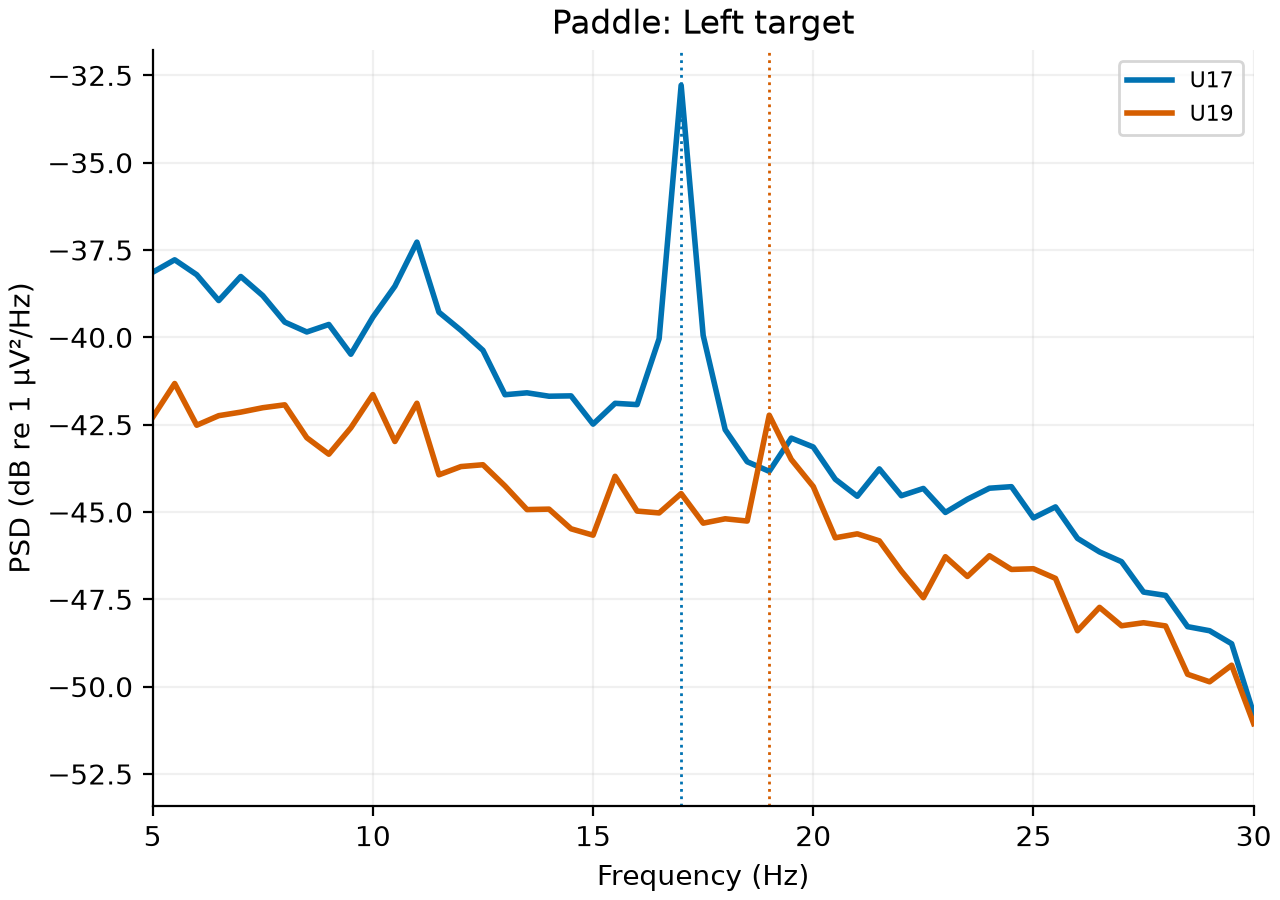
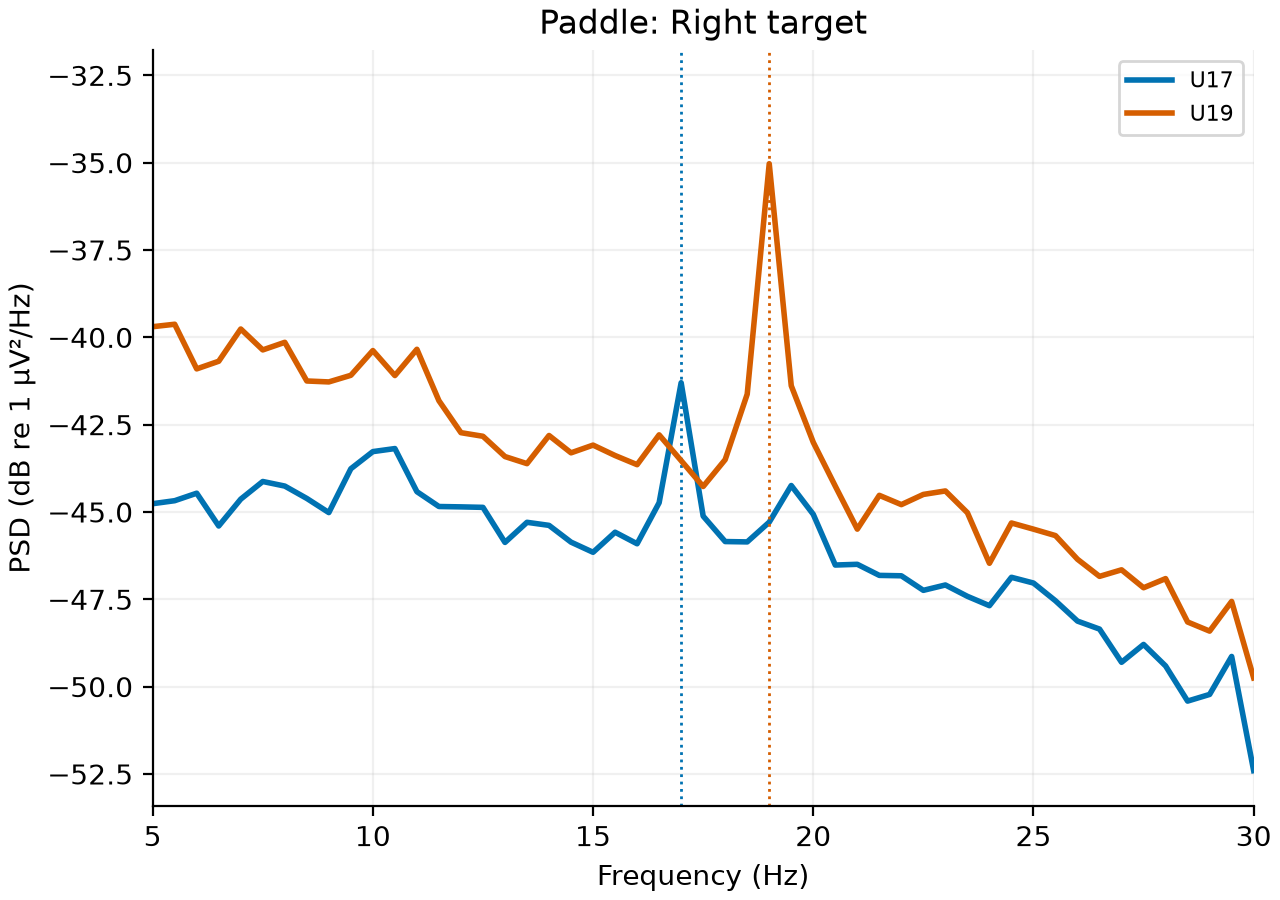
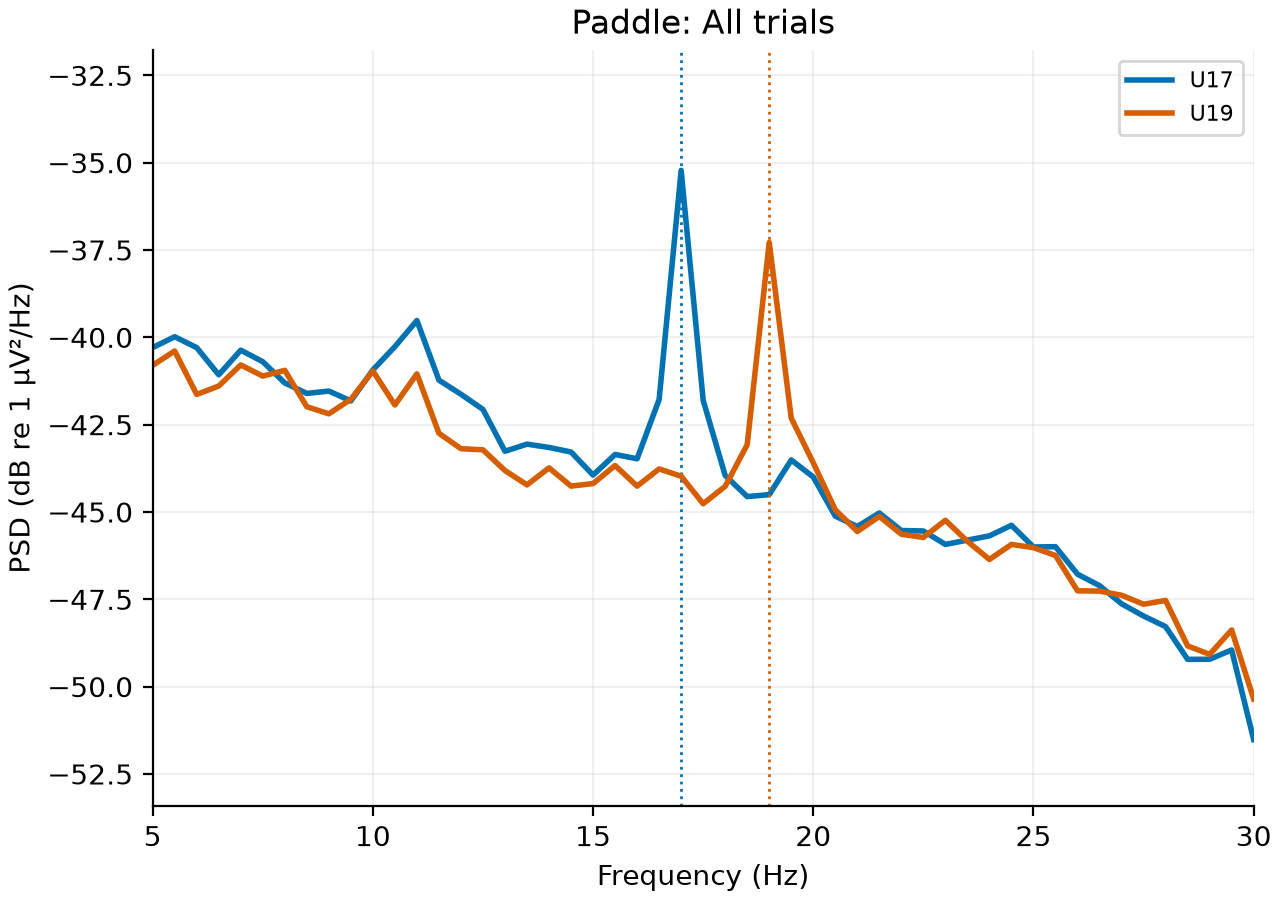
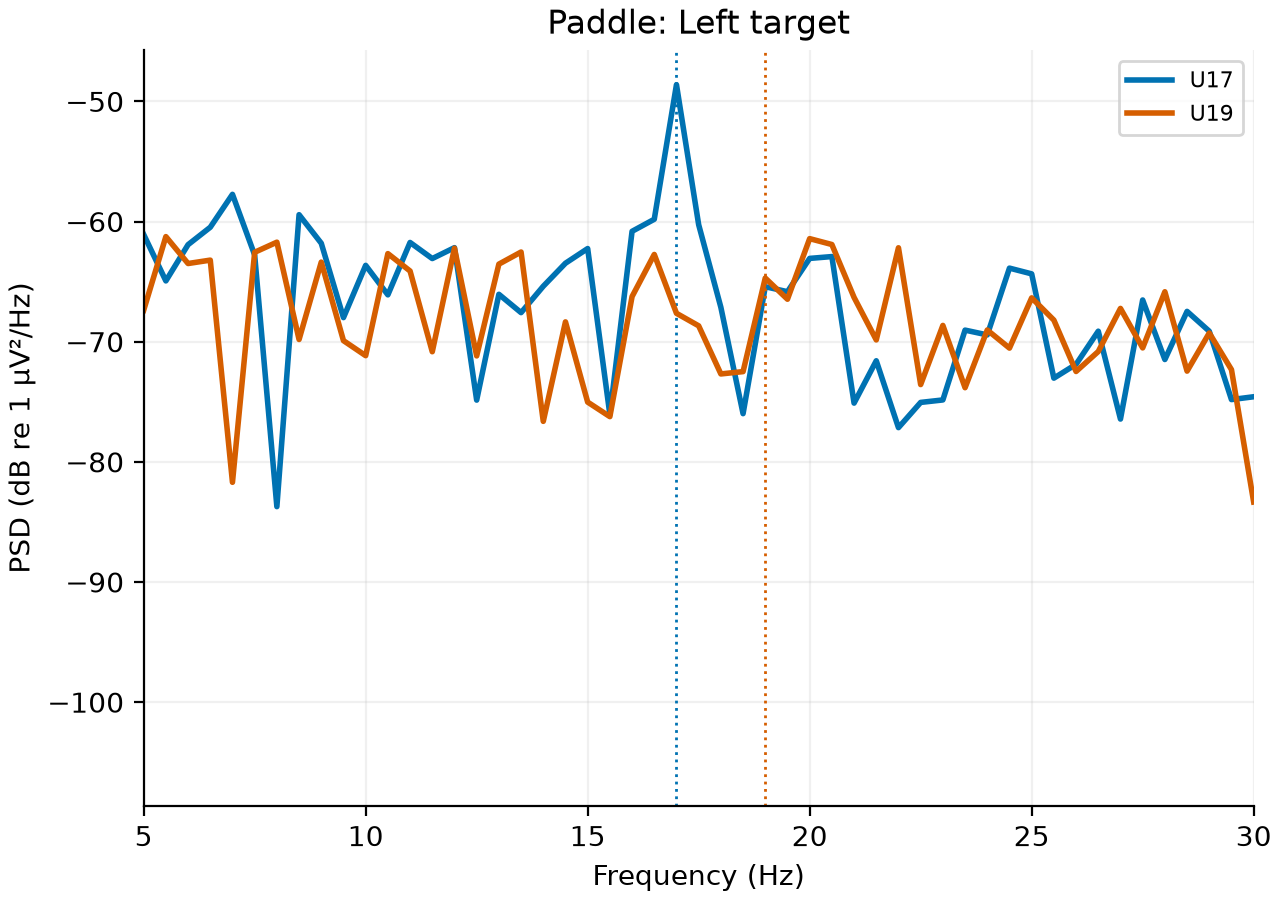
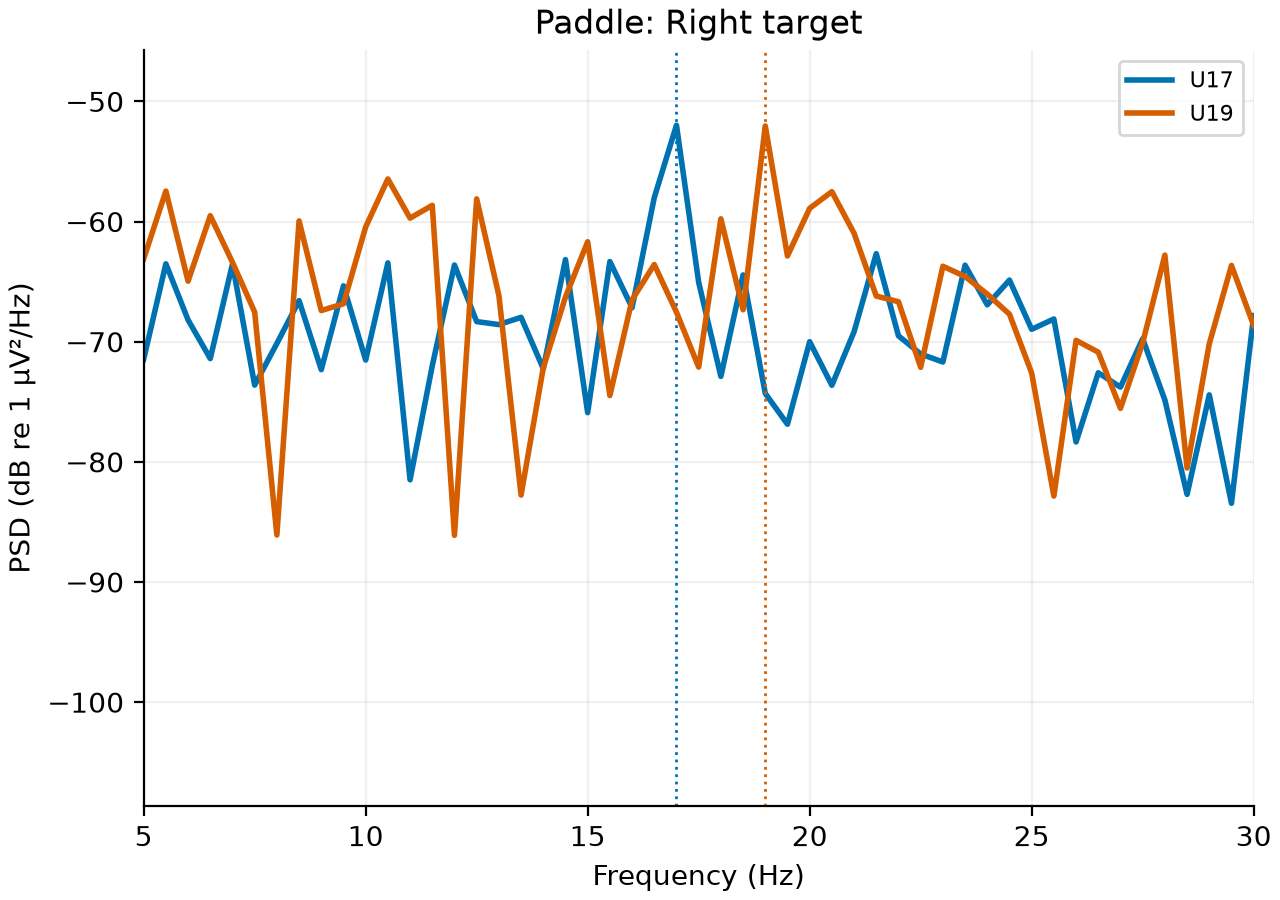
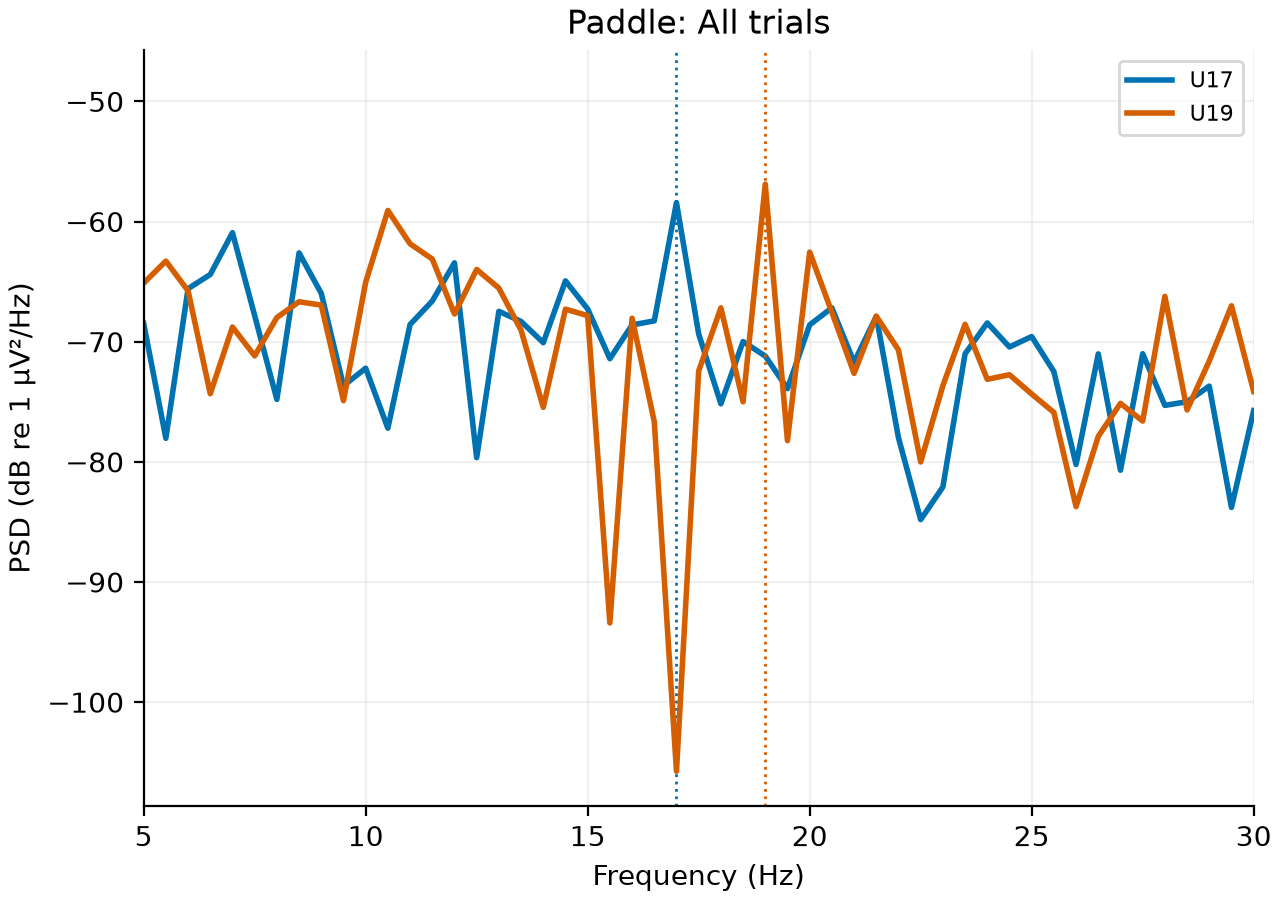


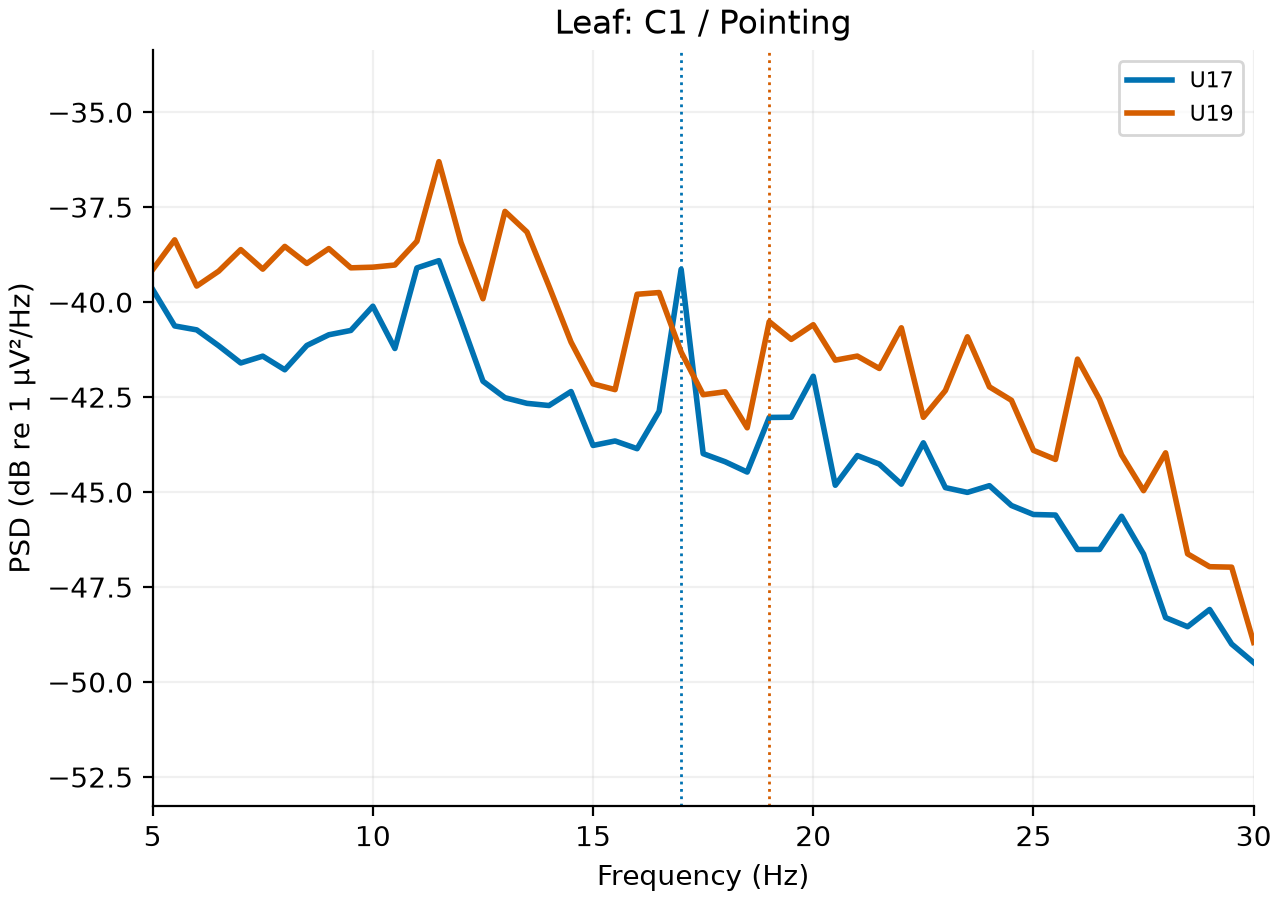
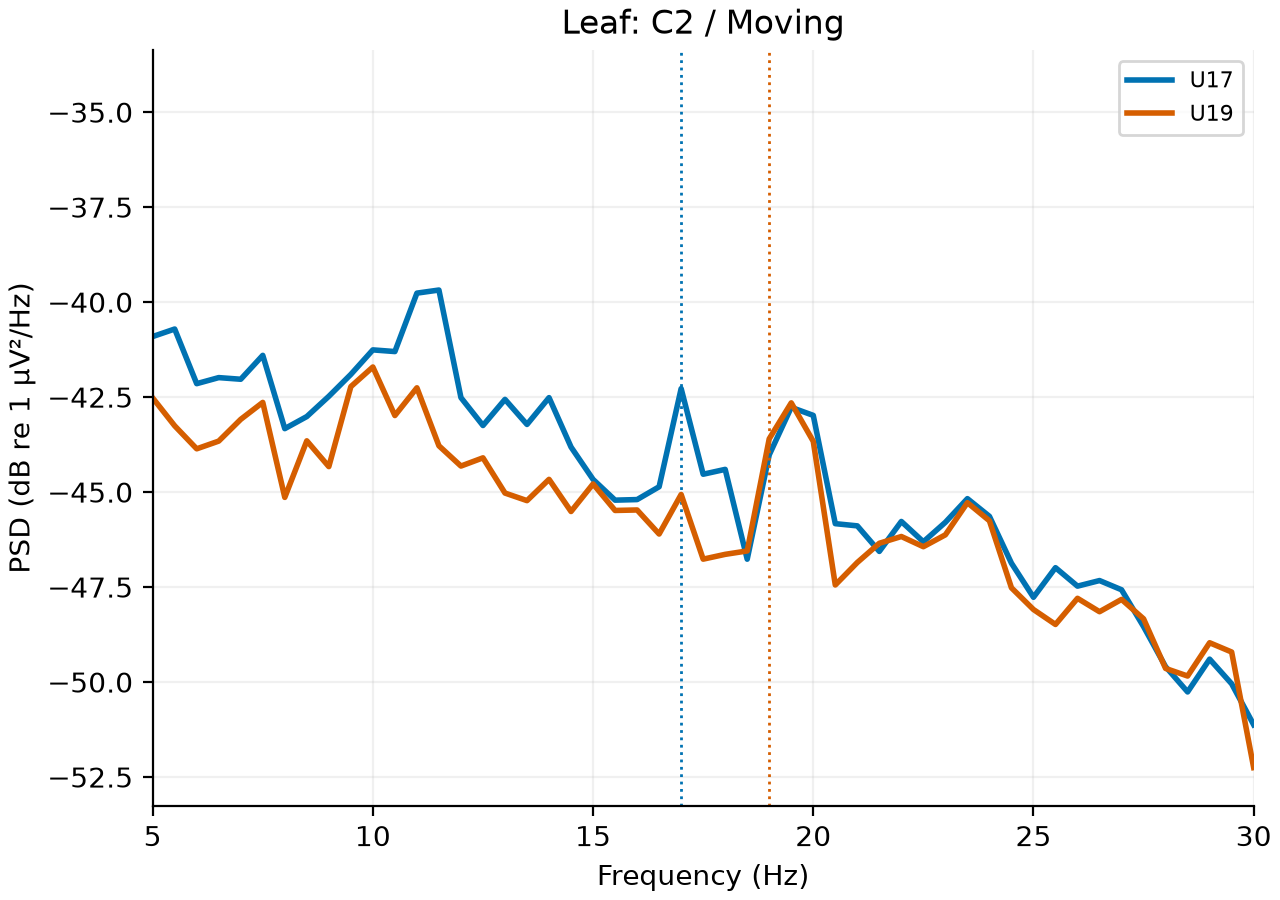
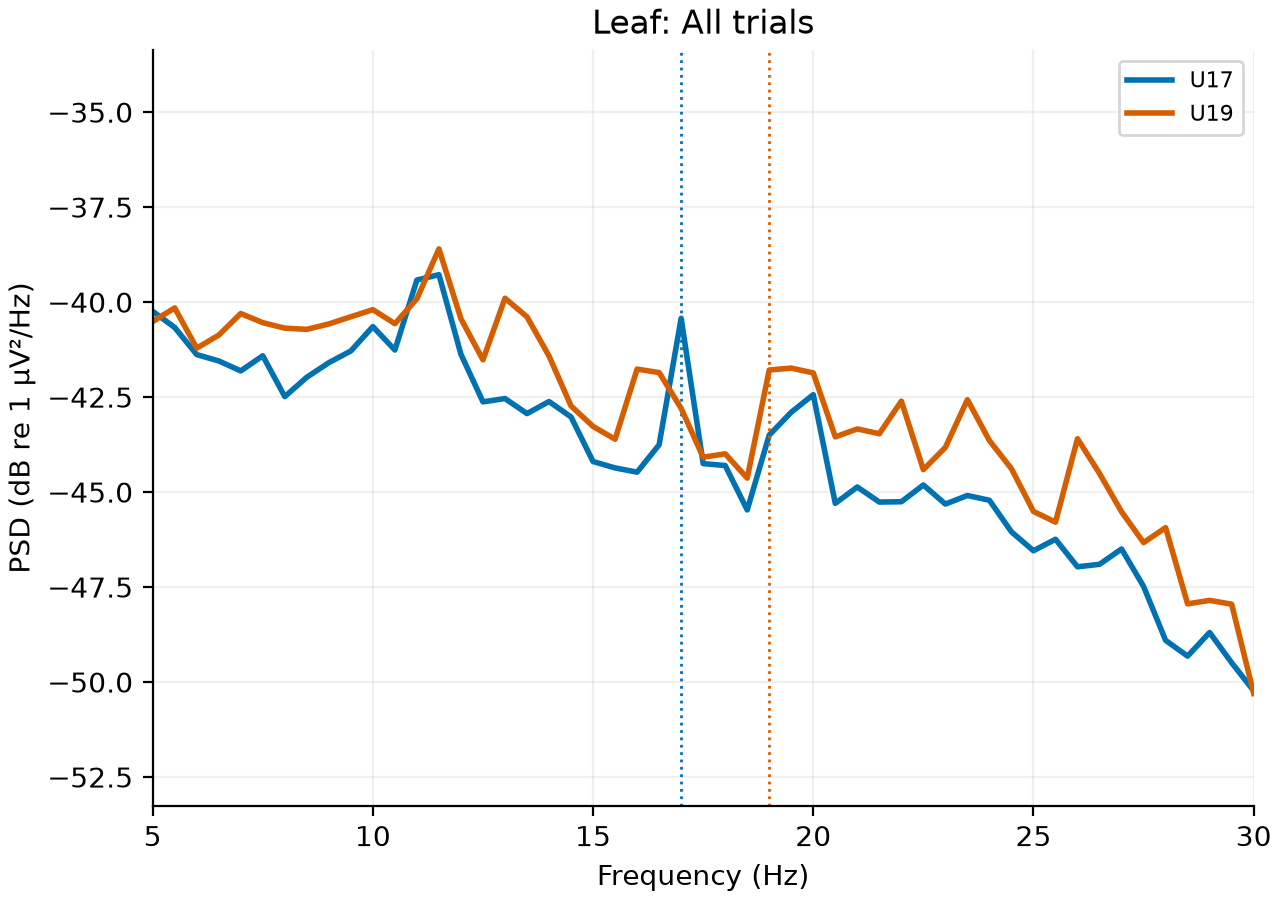
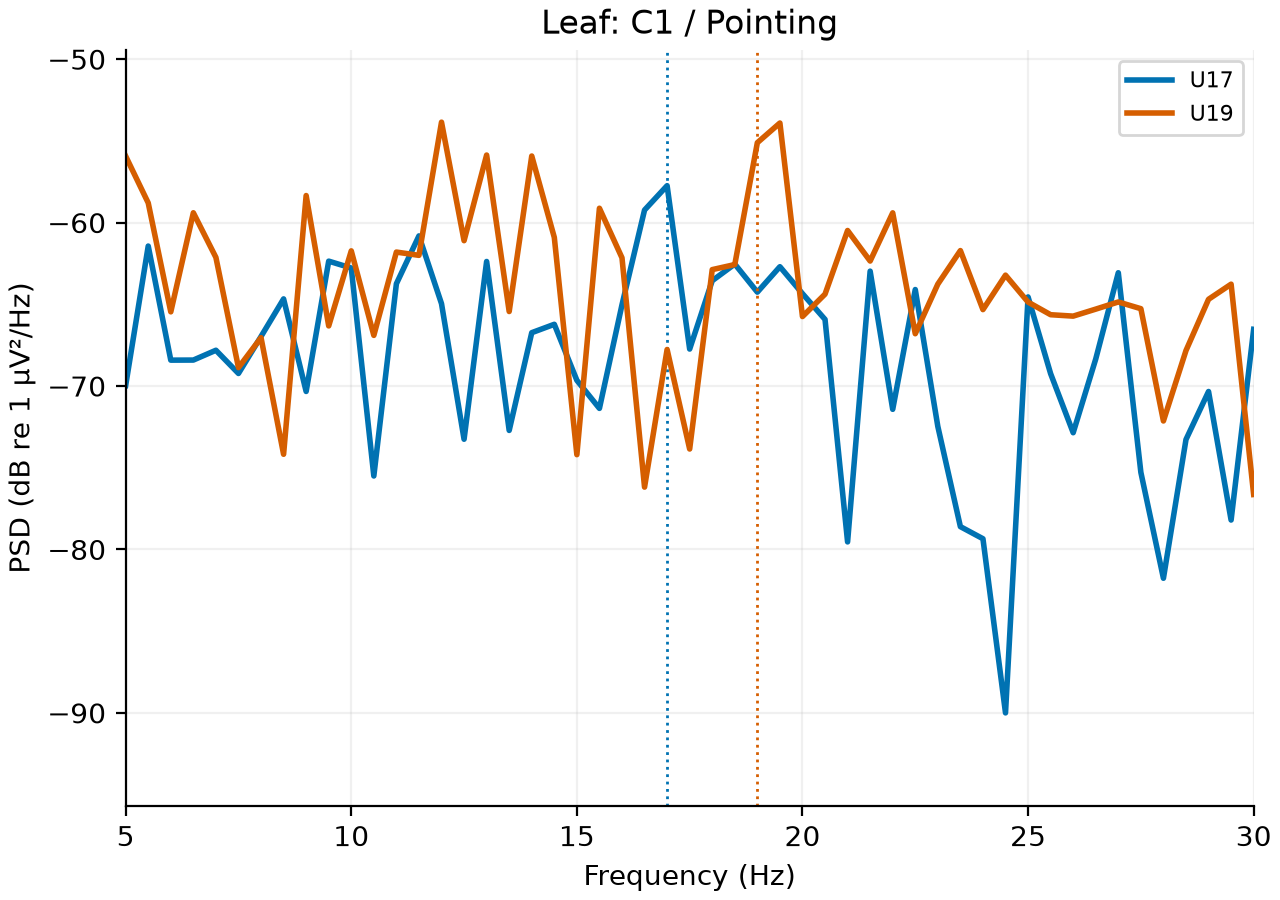
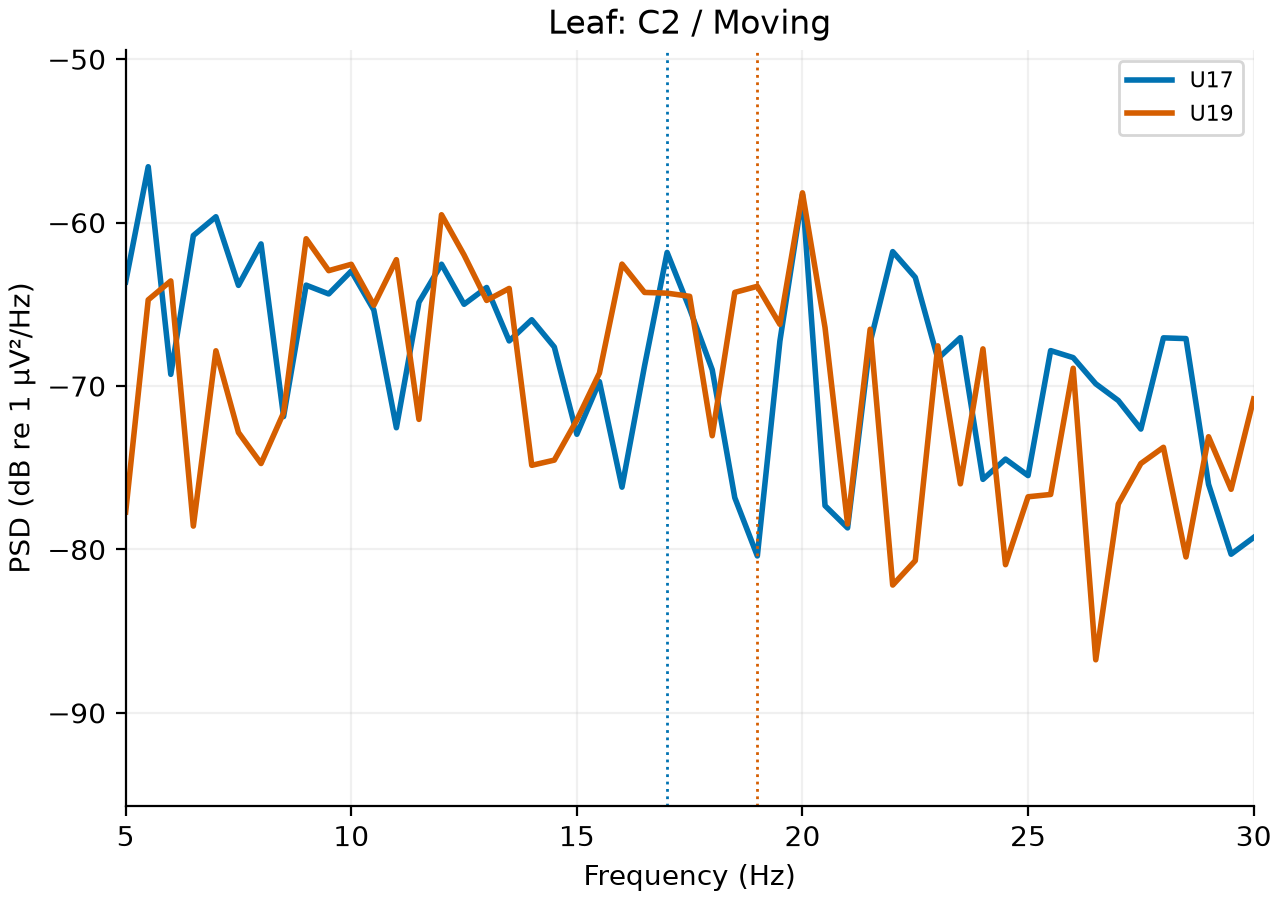
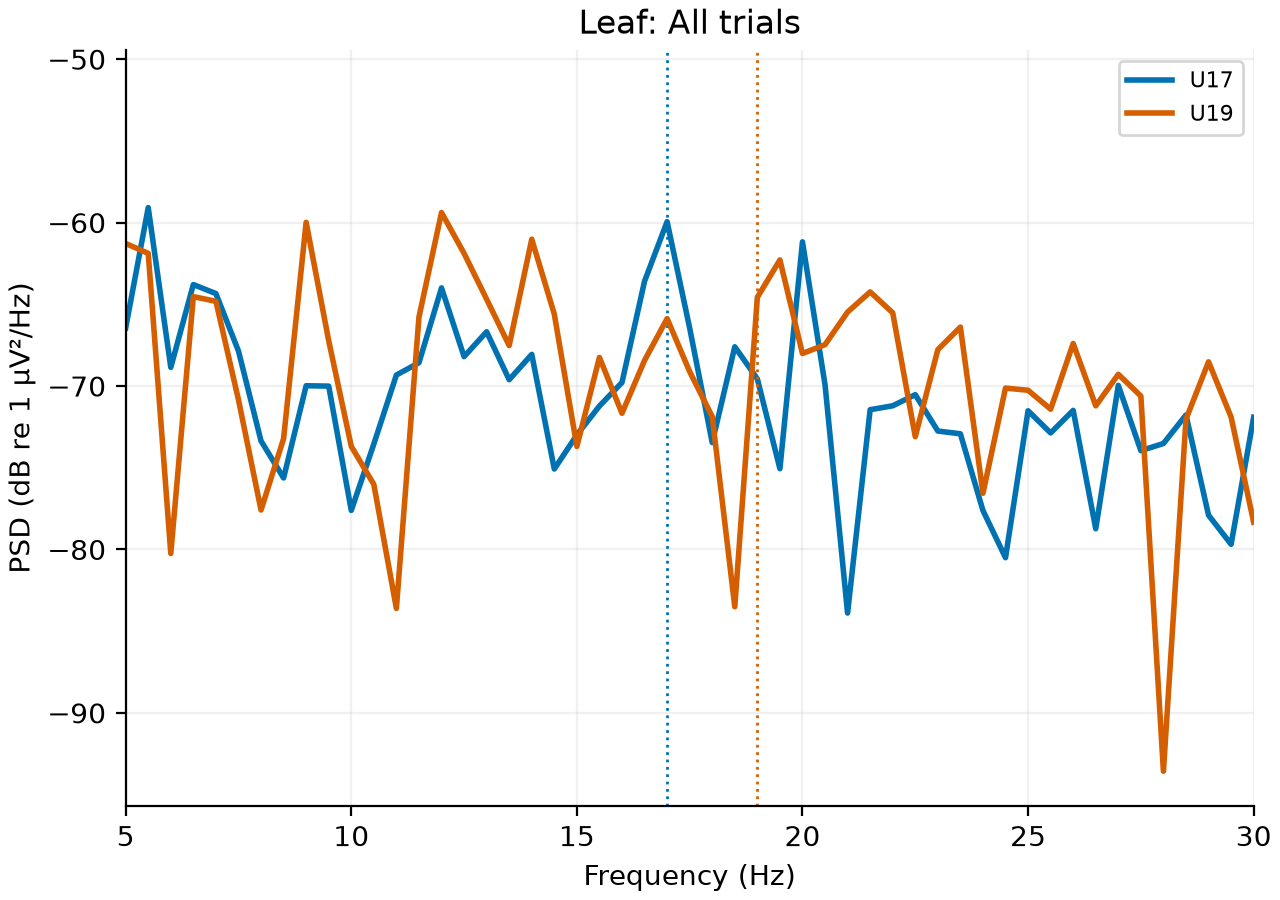


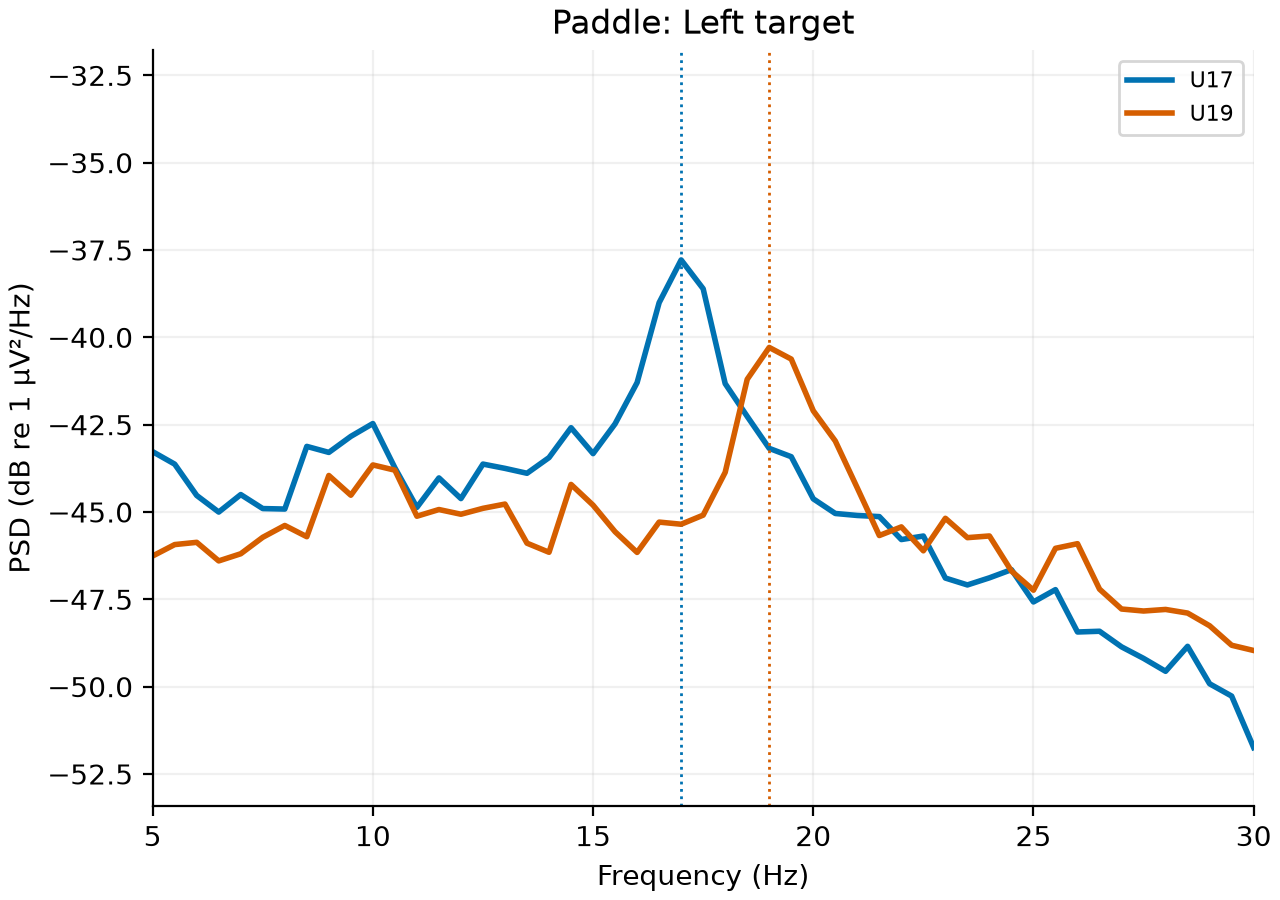
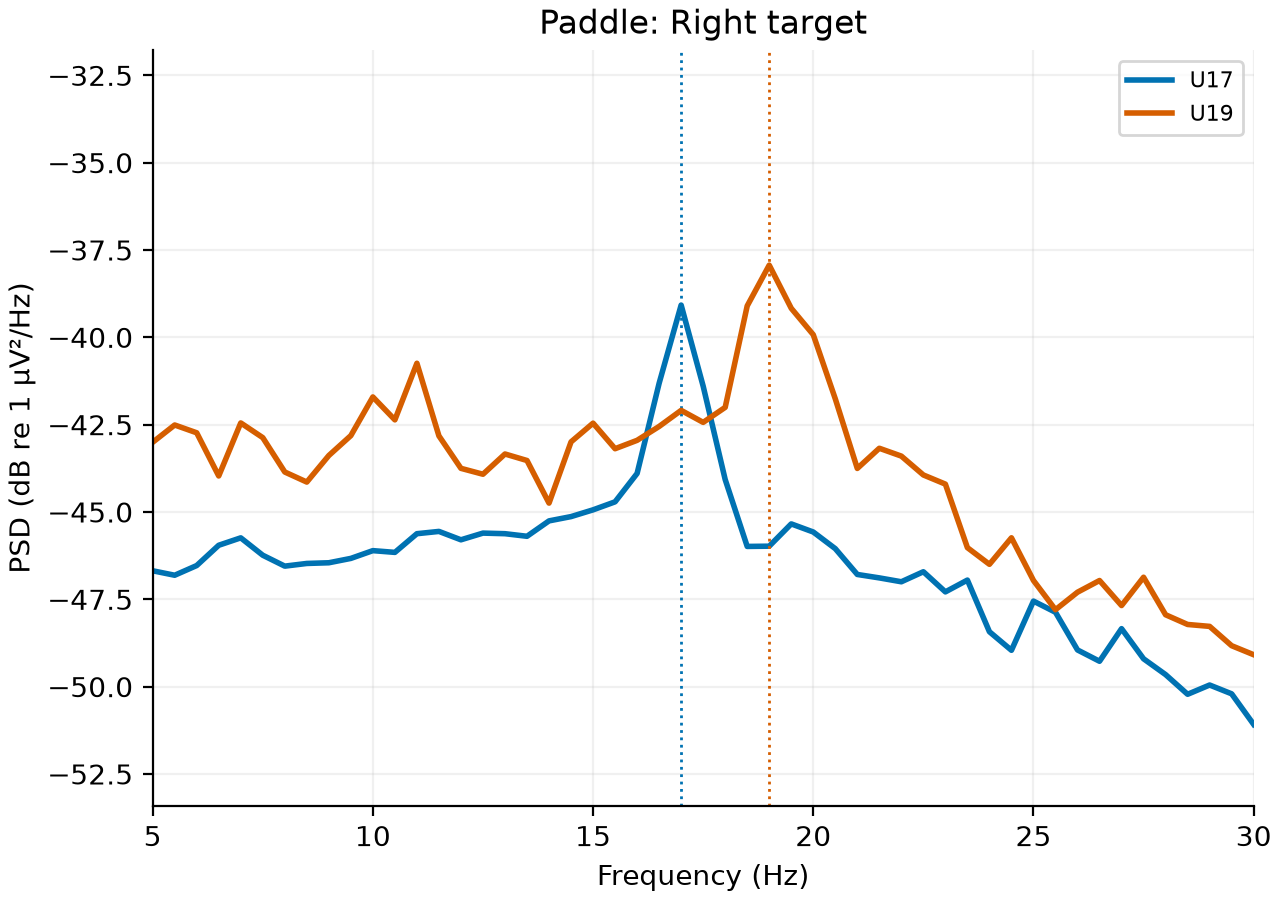
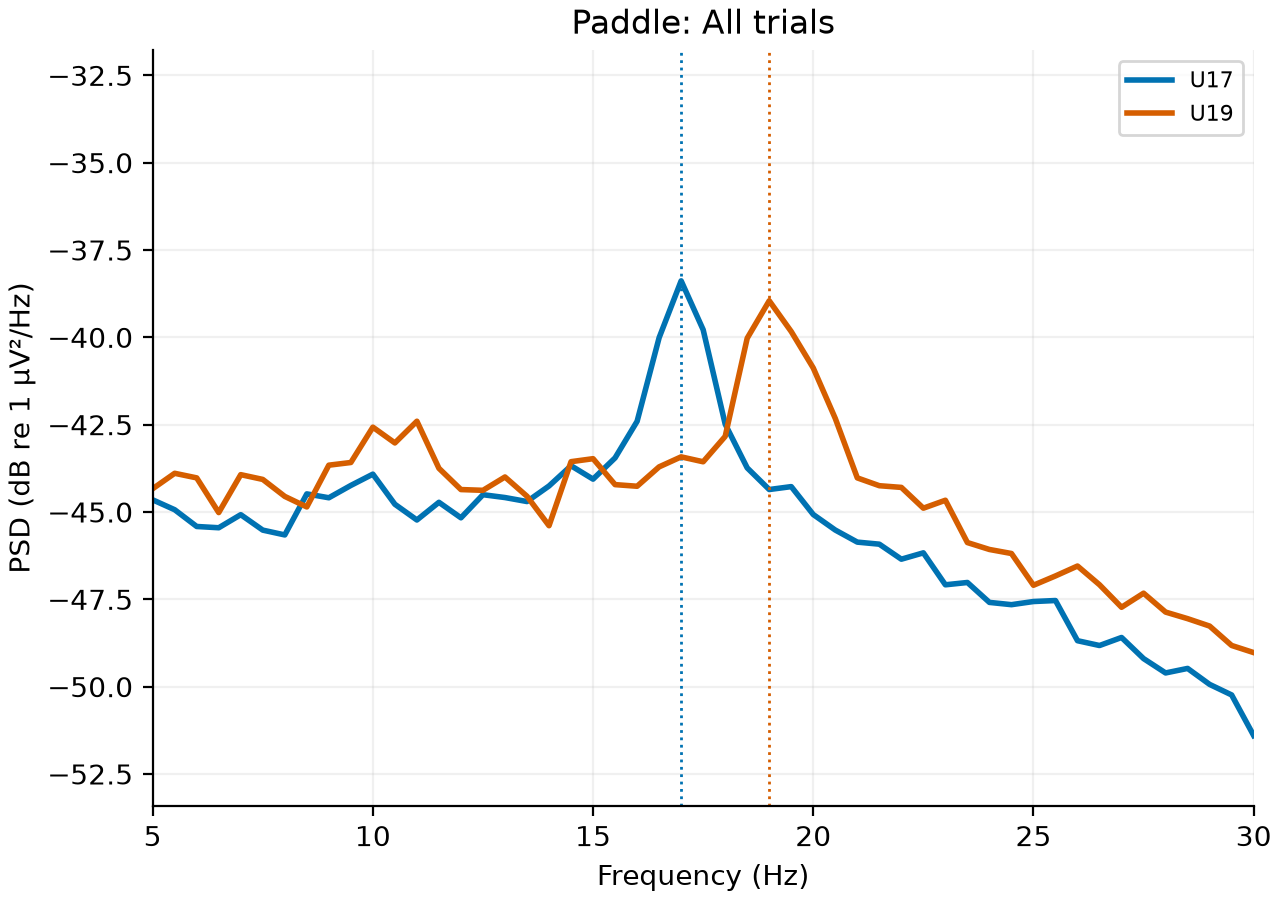
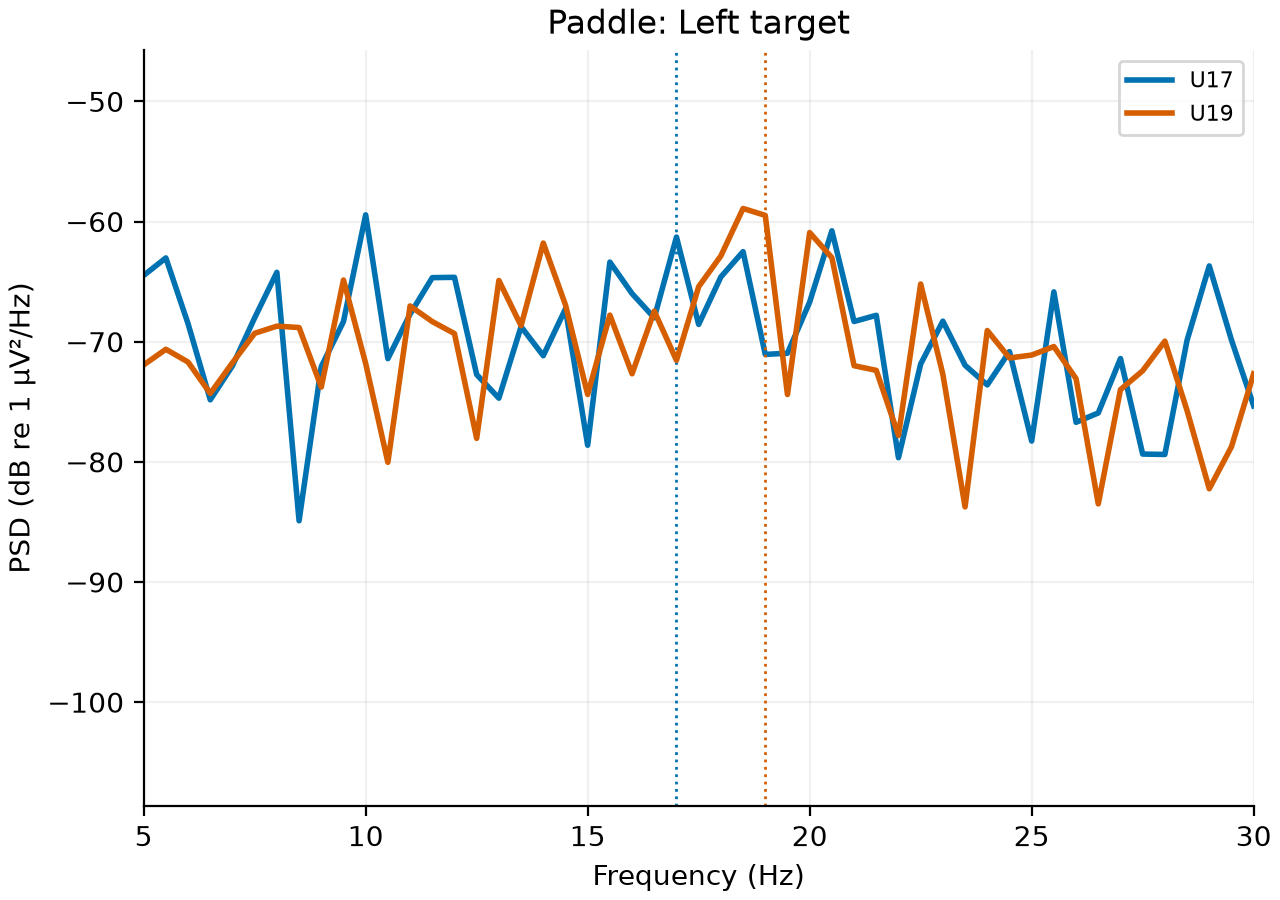
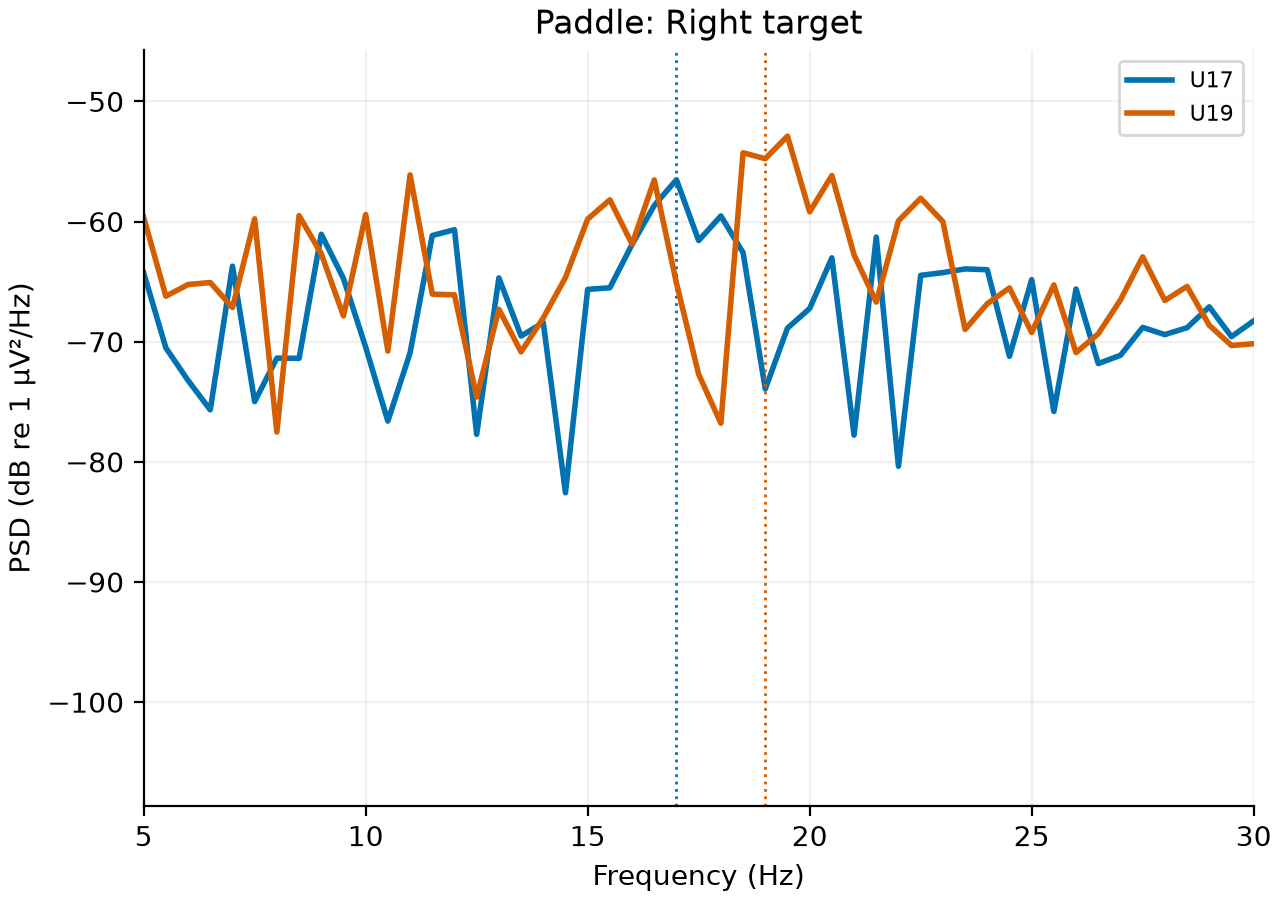
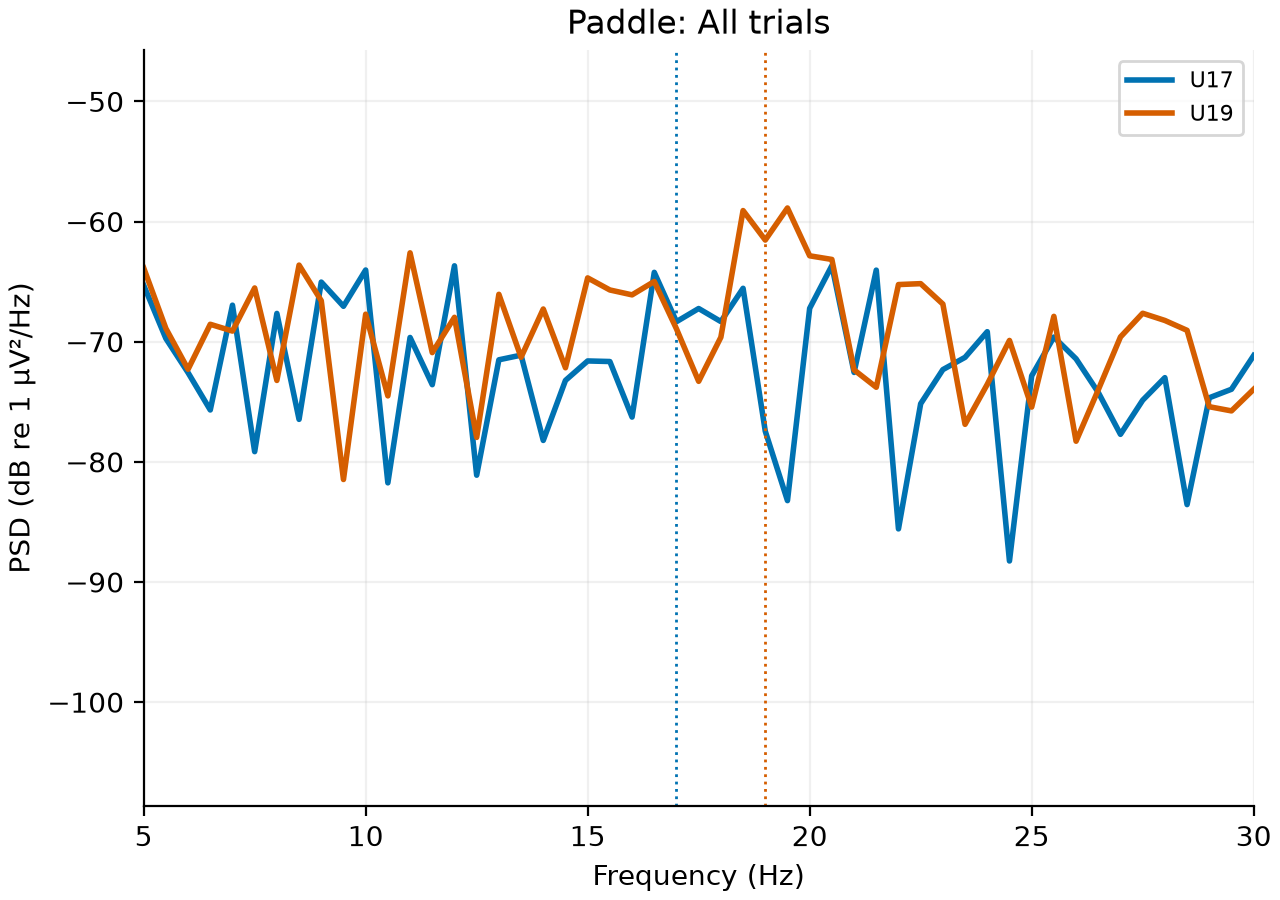


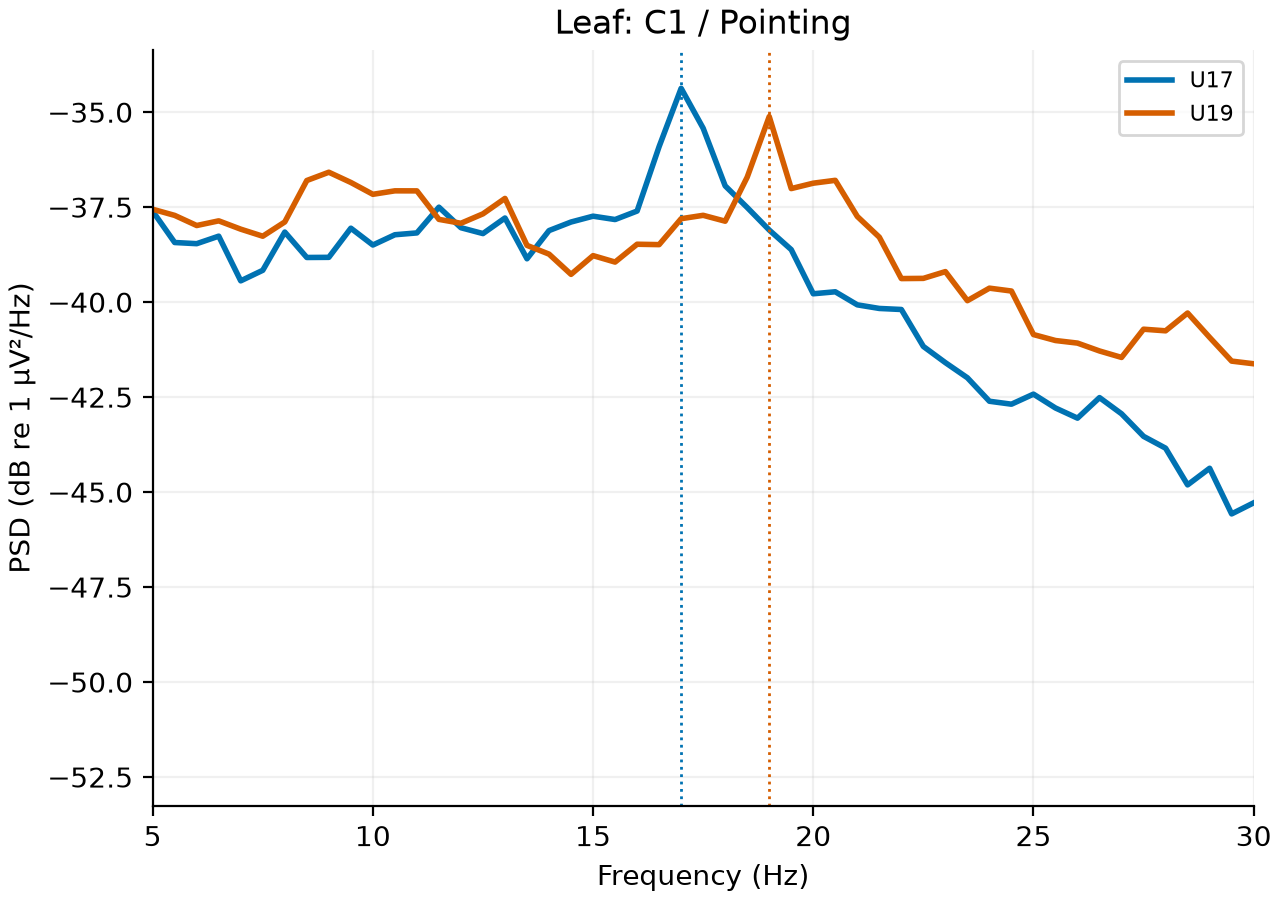
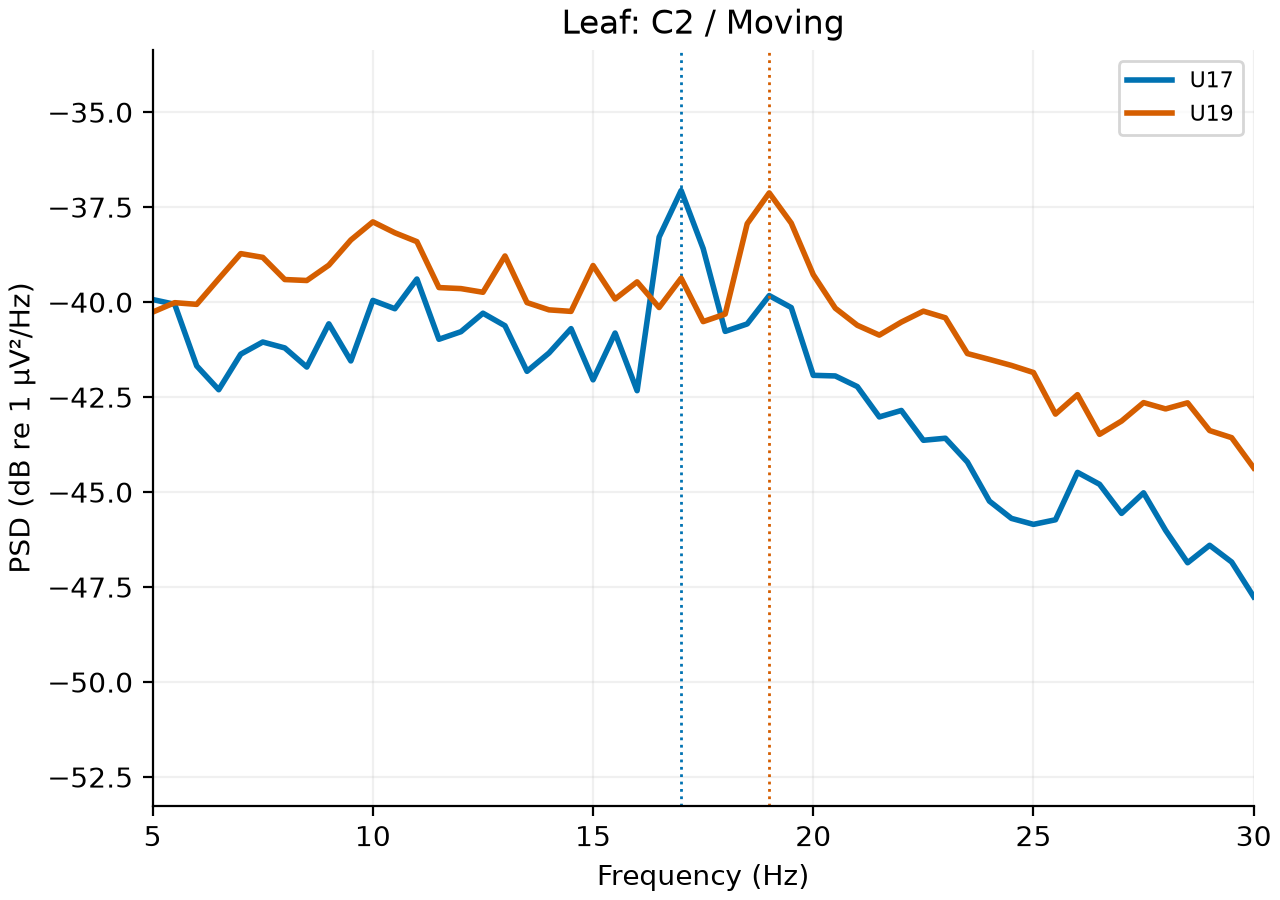
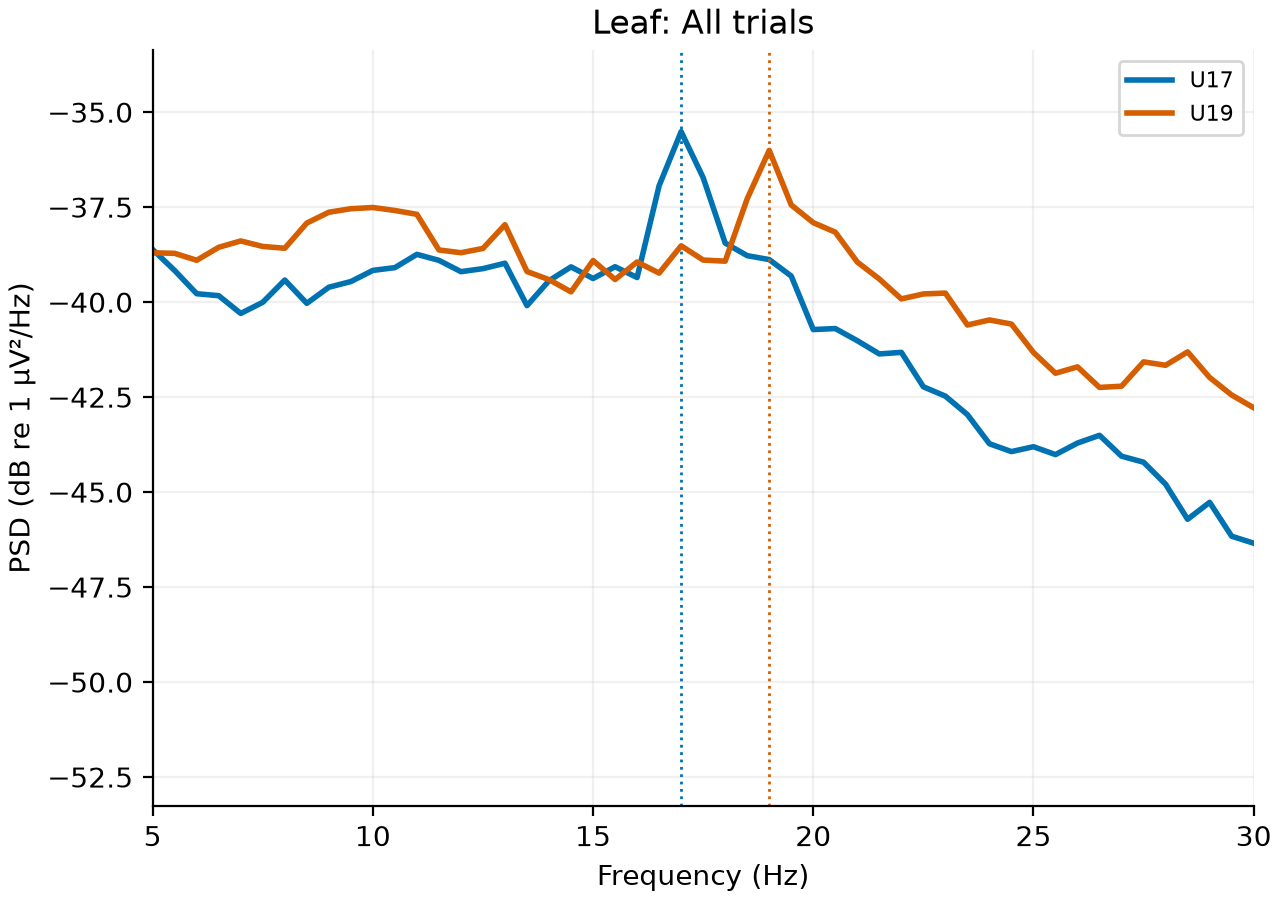
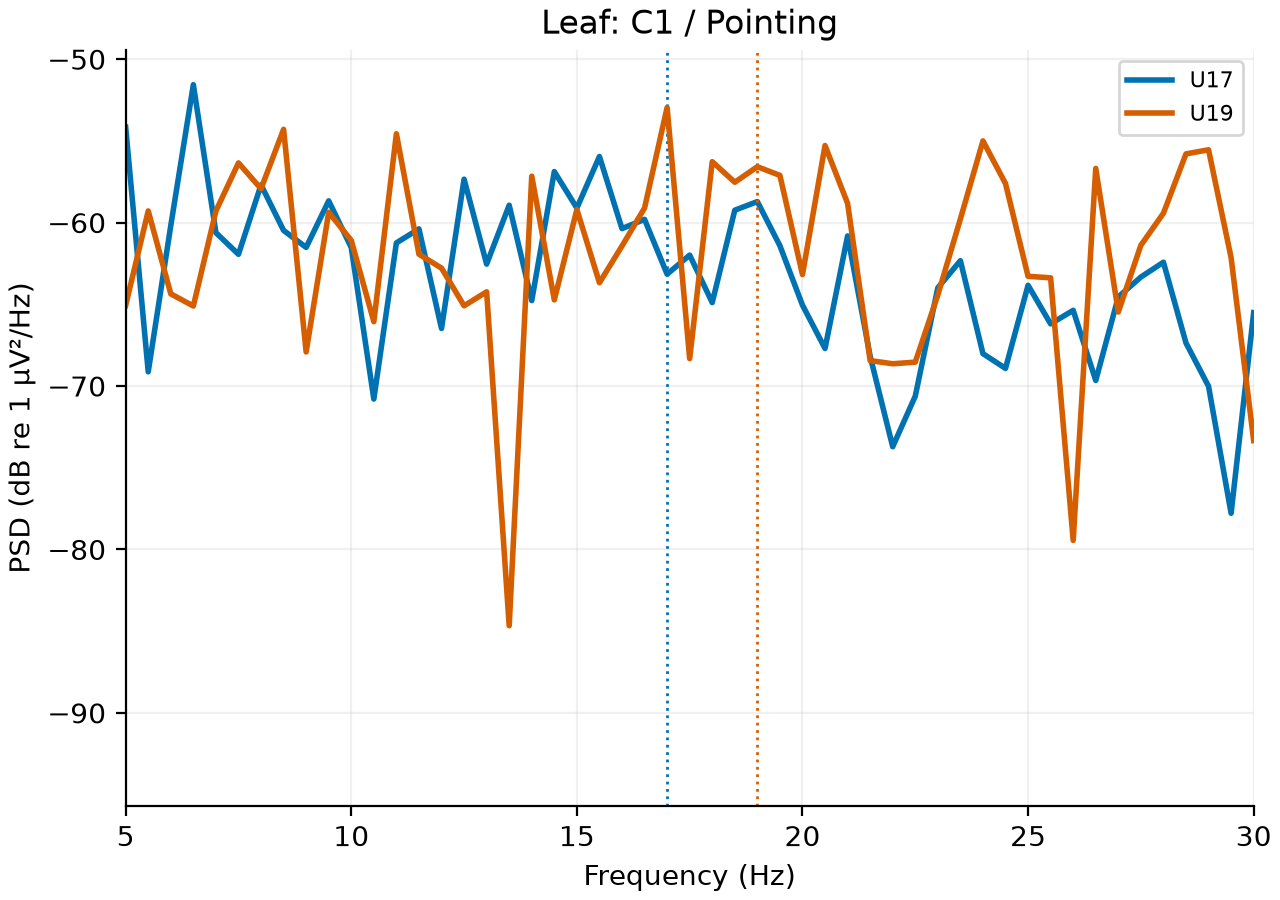
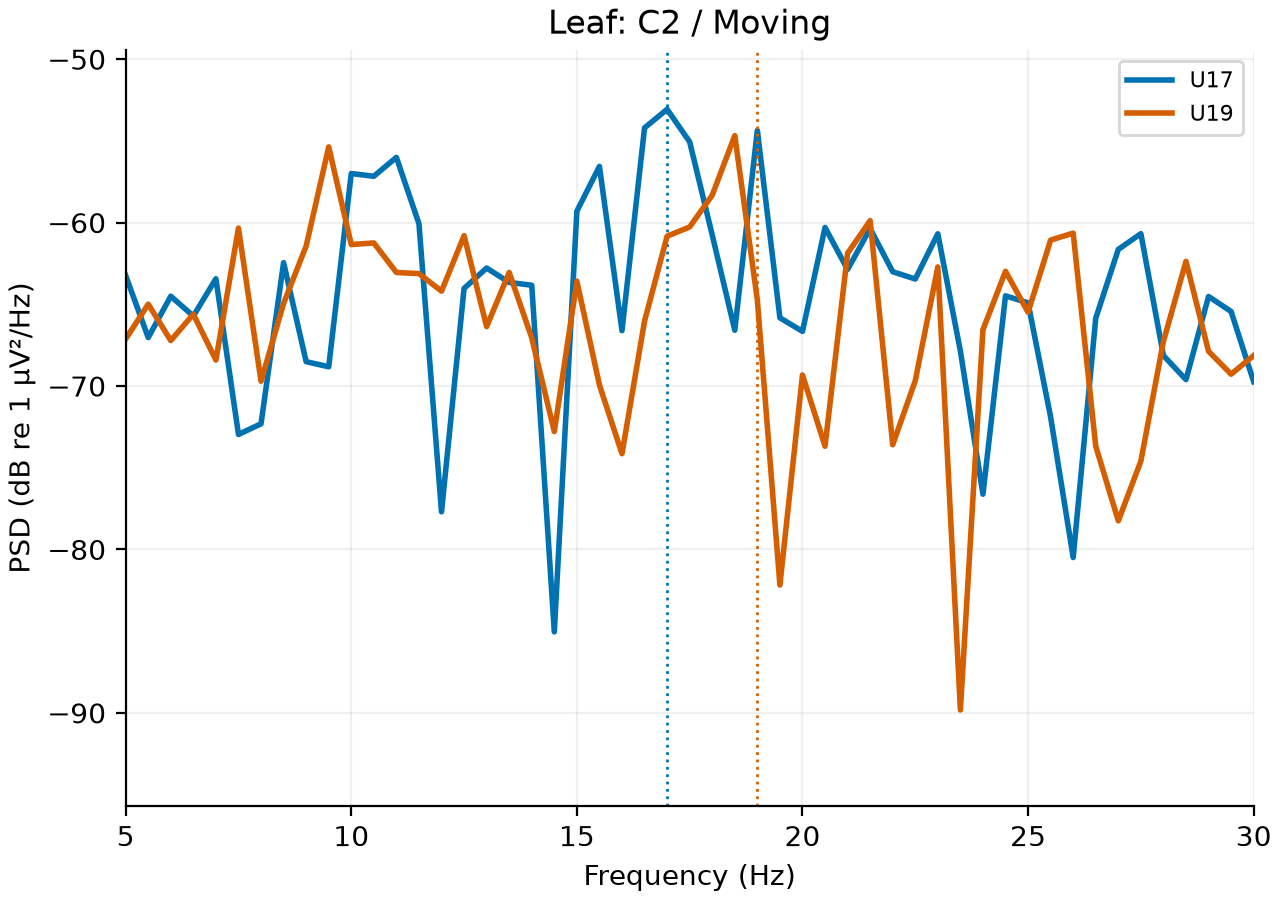
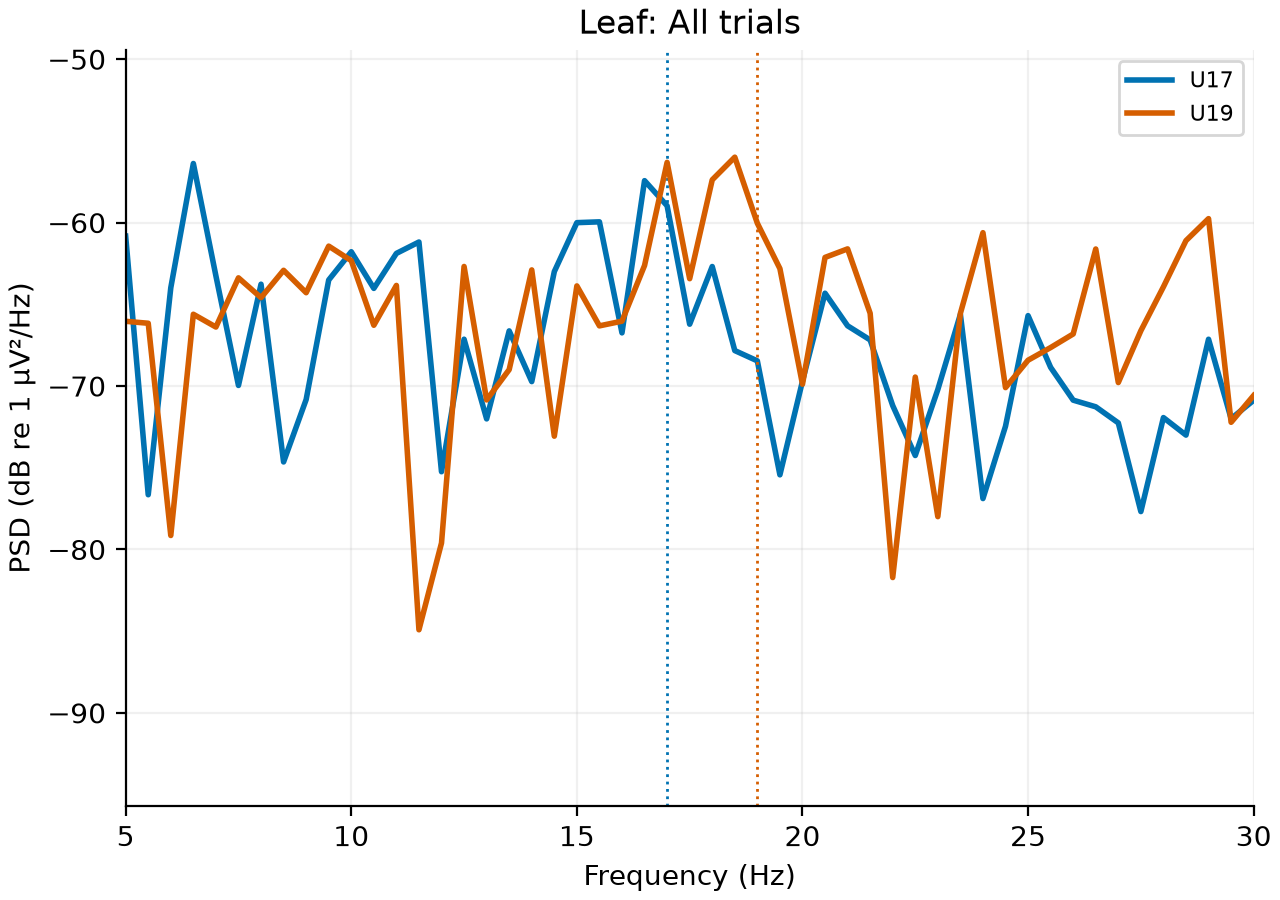

In [6]:
plot_exports = []
def slug(*parts):
    return '_'.join(re.sub(r'[^a-z0-9]+', '_', str(p).lower()).strip('_') for p in parts)

def db_plot(power):
    return 10*np.log10(np.maximum(power, np.finfo(float).tiny))

def common_limits(game, order):
    values = []
    for (g, condition, mode), s in summaries.items():
        if g != game:
            continue
        mask = (s['f'] >= FREQ_LIMITS[0]) & (s['f'] <= FREQ_LIMITS[1])
        values.extend(db_plot(s[order])[mask].ravel())
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    low, high = values.min(), values.max()
    pad = max((high-low)*.05, 1)
    return low-pad, high+pad

def spectrum_panel(s, game, condition, mode, order, ylim):
    name = condition or 'All trials'
    title = f'{game}: {name}'
    fig, ax = plt.subplots(figsize=(6.4, 4.5), constrained_layout=True)
    mask = (s['f'] >= FREQ_LIMITS[0]) & (s['f'] <= FREQ_LIMITS[1])
    for j, (hz, color) in enumerate(zip(TARGETS_HZ, ('#0072B2', '#D55E00'))):
        ax.plot(s['f'][mask], db_plot(s[order])[mask, j], color=color, lw=2, label=f'U{hz:g}')
        ax.axvline(hz, color=color, ls=':', lw=1)
    ax.set(title=title, xlabel='Frequency (Hz)', ylabel='PSD (dB re 1 µV²/Hz)', xlim=FREQ_LIMITS, ylim=ylim)
    ax.legend(fontsize=8)
    method = ('CCA weights fitted once using each entire trial' if mode == 'whole' else
              'CCA weights refitted on the latest 1 s every logged NF update (~100 ms)')
    averaging = ('Epoch PSDs averaged within each trial, then trials averaged equally' if order == 'induced' else
                 'NaN-aware epoch waveform means within trials, then equal trial waveform mean, then PSD')
    caption = (f'{method}. {averaging}. {s["n"]} trials; {s["epochs"]} {EPOCH_SECONDS:g}-second epochs '
               f'({s["complete"]} complete, {s["partial"]} partial). Final epochs have NaN tails. '
               f'Blue: U17; orange: U19. DPSS NW=1, K=1; {FS/EPOCH_SAMPLES:g} Hz FFT grid.')
    filename = slug(f'epoch{EPOCH_SECONDS:g}s', game, name, mode, order)
    png, svg = PLOT_EXPORT_DIR / f'{filename}.png', PLOT_EXPORT_DIR / f'{filename}.svg'
    fig.savefig(png, dpi=PLOT_EXPORT_DPI)
    fig.savefig(svg)
    plt.close(fig)
    encoded = base64.b64encode(png.read_bytes()).decode('ascii')
    plot_exports.append(dict(game=game, condition=name, method=mode, order=order, title=title,
                             caption=caption, png=str(png), svg=str(svg)))
    return (f'<img src="data:image/png;base64,{encoded}" style="width:100%;height:auto;display:block" alt="{html.escape(title)}">'
            f'<p style="font-size:12px;line-height:1.4">{html.escape(caption)}</p>'
            f'<a href="{html.escape(png.as_uri())}">PNG</a> · <a href="{html.escape(svg.as_uri())}">SVG</a>')

for mode in ('whole', 'refitted'):
    for game in FILES:
        conditions = [*LABELS[game].values(), None]
        title = f'{game} — ' + ('fixed whole-trial CCA weights' if mode == 'whole' else 'CCA weights refitted every 100 ms')
        columns = ''.join(f'<th>{html.escape(c or "All trials")}</th>' for c in conditions)
        rows = []
        for order in ('induced', 'evoked'):
            label = 'Spectrum first → average trials' if order == 'induced' else 'Average waveforms first → spectrum'
            panels = ''.join('<td style="width:33.3%;vertical-align:top;padding:8px;border:1px solid #ccc">' +
                spectrum_panel(summaries[(game, c, mode)], game, c, mode, order, common_limits(game, order)) + '</td>'
                for c in conditions)
            rows.append(f'<tr><td colspan="3"><strong>{html.escape(label)}</strong></td></tr><tr>{panels}</tr>')
        display(HTML(f'<h3>{html.escape(title)}</h3><table style="width:100%;table-layout:fixed;border-collapse:collapse">'
                     f'<thead><tr>{columns}</tr></thead><tbody>{"".join(rows)}</tbody></table>'))
pd.DataFrame(plot_exports).to_csv(PLOT_EXPORT_DIR / 'plot_manifest.csv', index=False)
print('24 independent figures: 12 fixed-weight and 12 refitted-weight; PNG/SVG files in', PLOT_EXPORT_DIR)

## Verify epoch coverage and padding

Check that epoching preserves every observed waveform sample, pads only missing tails, uses equal trial weighting, and produces exactly the requested 24 independent figures.

In [7]:
fragment = max(2, min(17, EPOCH_SAMPLES-1))
short = max(2, EPOCH_SAMPLES//2)
probe = epoch_trials([np.arange(float(EPOCH_SAMPLES+fragment)), np.arange(float(short))], EPOCH_SAMPLES)
assert probe.shape == (2, 2, EPOCH_SAMPLES)
assert np.array_equal(probe[0, 0], np.arange(float(EPOCH_SAMPLES)))
assert np.array_equal(probe[0, 1, :fragment], np.arange(float(EPOCH_SAMPLES), float(EPOCH_SAMPLES+fragment)))
assert np.isnan(probe[0, 1, fragment:]).all() and np.isnan(probe[1, 1]).all()
for (game, condition, mode), s in summaries.items():
    key = 'fixed_u' if mode == 'whole' else 'refitted_u'
    for i, t in enumerate(s['chosen']):
        flattened = s['padded'][i].reshape(-1, len(TARGETS_HZ))
        assert np.array_equal(flattened[:len(t['x'])], t[key])
        assert np.isnan(flattened[len(t['x']):]).all()
    assert np.allclose(s['induced'], finite_mean(s['trial_power'], axis=0))
    assert np.allclose(s['evoked'], nan_epoch_psd(s['mean_epoch'], FS, EPOCH_SAMPLES)[1])
    assert np.isfinite(s['induced']).all() and np.isfinite(s['evoked']).all()
    assert np.isclose(np.diff(s['f']), FS/EPOCH_SAMPLES).all()
for t in eligible_trials:
    assert len(t['fixed_u']) == len(t['refitted_u']) == len(t['x'])
    for update in t['update_fits']:
        if update['hi'] > update['lo']:
            a, b = update['lo']-t['start'], update['hi']-t['start']
            expected = np.column_stack([(t['x'][a:b]-fit['x_mean']) @ fit['w'] for fit in update['fits']])
            assert np.allclose(t['refitted_u'][a:b], expected)
assert len(plot_exports) == 24
assert len({r['png'] for r in plot_exports}) == 24
assert all(Path(r[ext]).is_file() for r in plot_exports for ext in ('png', 'svg'))
assert epoch_audit.observed_samples.sum() == sum(len(t['x']) for t in eligible_trials)
assert epoch_audit.groupby('uid').observed_samples.sum().sum() == sum(len(t['x']) for t in eligible_trials)
print(f'All {len(eligible_trials)} complete projected trials retained; {EPOCH_SECONDS:g}-second epoch coverage, NaN tails, both orders and 24 figures verified.')

All 144 complete projected trials retained; 2-second epoch coverage, NaN tails, both orders and 24 figures verified.
